# Microbiome Features That Stratify the Defense Score: Stricter and Looser Gene Selection

Repeats `microbiome_features_stratifying_log2_defense_score.ipynb` with two new defense scores. The genes are selected the same way as in `load_correlated_immunity_genes_plates_1_to_5.ipynb`: defense GO-term genes (plus Luke's non-self-recognition set) and flg22-induced genes, kept if their Pearson r with total load (`ham16s`) across long-term samples is above a cutoff. Only the cutoff changes:

- **Stricter:** r > 0.5
- **Looser:** r > 0.3
- (The existing score uses r > 0.4. It's included in the gene-set comparison and the final summary for reference.)

Both scores use the log2 version: z-score of log2(TPM + 1), summed and divided by the number of genes. Transcriptomes with fewer than 250,000 total reads are dropped. The full stratification analysis then runs once per score, each under its own heading, followed by a side-by-side summary.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy.stats import zscore
from skbio.diversity.alpha import shannon
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score

###Define Thresholds
core_prevalence_threshold = 0.8
rare_prevalence_threshold = 0.1
ultra_rare_prevalence_threshold = 0.05
min_group_size = 10  # smallest group allowed in a presence / co-presence split
min_prevalence_abundance_test = 0.2
pair_prevalence_range = (0.1, 0.9)
genus_pseudocount = 0.05  # % of reads (detection floor), for the log-transformed abundance
n_permutations = 100
random_seed = 0

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata = metadata.drop(
    columns=[
        "arb.sort",
        "sample-id",
        "Ambiguous Unstranded",
        "Ambiguous Forward",
        "Multimapping",
        "Unmapped Over Mapped",
    ]
)
metadata["Date and Time"] = metadata["date"] + " " + metadata["time"]
luke_time_data_format = "%-m/%-d/%y %-H:%-M"
metadata["Date and Time"] = pd.to_datetime(
    metadata["Date and Time"], format=luke_time_data_format
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


## Gene selection at different load-correlation cutoffs

In [3]:
arabi_go_matrix = pd.read_csv(
    "/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv",
    index_col=0,
)
defense_terms = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Defense_go_terms.csv"
)

# Luke's custom non-self-recognition gene set, added as its own "GO term"
non_self_recognition_genes = [
    "AT1G02920",
    "AT1G02930",
    "AT1G21110",
    "AT1G21120",
    "AT1G26380",
    "AT1G26410",
    "AT1G26420",
    "AT1G35230",
    "AT1G64170",
    "AT1G65500",
    "AT1G76930",
    "AT2G19190",
    "AT2G25470",
    "AT2G30750",
    "AT2G39200",
    "AT2G43620",
    "AT3G46280",
    "AT4G12490",
    "AT4G12500",
    "AT4G23140",
    "AT4G23220",
    "AT4G28420",
    "AT5G24110",
    "AT5G64120",
]
defense_terms.loc[len(defense_terms)] = [
    "GO:Luke Custom",
    "General Non Self Recognition Genes",
    "Custom From Luke",
]
arabi_go_matrix["GO:Luke Custom"] = 0
arabi_go_matrix.loc[non_self_recognition_genes, "GO:Luke Custom"] = 1

go_to_genes = {}
for go_term in defense_terms["GO Term ID"].unique():
    if go_term not in arabi_go_matrix.columns:
        print(f"Warning: GO term {go_term} not found in the matrix, skipping.")
        continue
    go_to_genes[go_term] = set(arabi_go_matrix.index[arabi_go_matrix[go_term] == 1])
    print(f"{go_term}: {len(go_to_genes[go_term])} genes")

go_term_genes = set().union(*go_to_genes.values())
print(f"\nUnique GO-term genes: {len(go_term_genes)}")

GO:0012501: 34 genes
GO:0009626: 54 genes
GO:0042742: 325 genes
GO:0071219: 7 genes
GO:0045087: 58 genes
GO:0009862: 16 genes
GO:0009861: 11 genes
GO:0034055: 1 genes
GO:0009682: 21 genes
GO:0009627: 57 genes
GO:0002237: 41 genes
GO:0010421: 2 genes
GO:0016045: 4 genes
GO:0009617: 153 genes
GO:1900425: 17 genes
GO:1900426: 30 genes
GO:1900424: 9 genes
GO:0002253: 1 genes
GO:0002218: 1 genes
GO:0002758: 13 genes
GO:0002757: 2 genes
GO:0006955: 15 genes
GO:0050776: 6 genes
GO:0009609: 2 genes
GO:Luke Custom: 24 genes

Unique GO-term genes: 663


In [4]:
flg_genes = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/shared_flg_induced_genes.csv"
)
flg_arabidopsis_genes = (
    flg_genes["Arabidopsis_thaliana"].dropna().astype(str).str.strip()
)
flg_arabidopsis_genes = set(
    gene for gene in flg_arabidopsis_genes if gene not in ["", "nan", "None"]
)
print(f"FLG Arabidopsis genes: {len(flg_arabidopsis_genes)}")

FLG Arabidopsis genes: 868


In [5]:
load_cutoffs = [0.5, 0.4, 0.3]

long_term_metadata = trimmed_metadata.loc[trimmed_metadata["Experiment Type"] == "Long Term"]
long_term_transcriptome = trimmed_transcriptome.loc[long_term_metadata.index]
total_load_df = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv",
    index_col=0,
)
ham16s_by_filename = long_term_metadata["sampID"].map(total_load_df["ham16s"])
print("Long-term samples with ham16s:", ham16s_by_filename.notna().sum())

# Pearson r of every GO-term / FLG gene with total load, across long-term samples
candidate_genes = sorted((go_term_genes | flg_arabidopsis_genes) & set(long_term_transcriptome.columns))
pearson_with_load = long_term_transcriptome[candidate_genes].corrwith(ham16s_by_filename)

gene_sets = {}
gene_set_rows = []
for cutoff in load_cutoffs:
    go_over = set(pearson_with_load.index[pearson_with_load.index.isin(go_term_genes) & (pearson_with_load > cutoff)])
    flg_over = set(pearson_with_load.index[pearson_with_load.index.isin(flg_arabidopsis_genes) & (pearson_with_load > cutoff)])
    gene_sets[f"r > {cutoff}"] = sorted(go_over | flg_over)
    gene_set_rows.append(
        {"cutoff": f"r > {cutoff}", "FLG genes": len(flg_over), "GO-term genes": len(go_over),
         "in both": len(go_over & flg_over), "union": len(go_over | flg_over)}
    )
    if cutoff != 0.4:  # the 0.4 list is written by load_correlated_immunity_genes_plates_1_to_5.ipynb
        pd.DataFrame(
            {"gene": gene_sets[f"r > {cutoff}"], "pearson_r_load": pearson_with_load[gene_sets[f"r > {cutoff}"]].values}
        ).sort_values("pearson_r_load", ascending=False).to_csv(
            f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5_r{cutoff}.csv", index=False
        )
pd.DataFrame(gene_set_rows).set_index("cutoff")

Long-term samples with ham16s: 222


/Users/michael/miniconda3/envs/Luke_terrace/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/michael/miniconda3/envs/Luke_terrace/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,FLG genes,GO-term genes,in both,union
cutoff,,,,
r > 0.5,15,33,2,46
r > 0.4,63,96,11,148
r > 0.3,172,184,23,333


In [6]:
# log2 defense score for each gene set, on all transcriptome samples
log_expression = np.log2(trimmed_transcriptome + 1)
defense_scores = pd.DataFrame(
    {name: log_expression[genes].apply(zscore).sum(axis=1) / len(genes) for name, genes in gene_sets.items()}
)
print("Gene-set overlaps (shared genes):")
display(pd.DataFrame(
    [[len(set(gene_sets[a]) & set(gene_sets[b])) for b in gene_sets] for a in gene_sets],
    index=list(gene_sets), columns=list(gene_sets),
))
print("Spearman correlation between the scores (all samples):")
display(defense_scores.corr(method="spearman").round(3))
top_sets = {name: set(defense_scores[name].nlargest(25).index) for name in defense_scores}
print("Overlap of the top 25 samples:")
pd.DataFrame(
    [[len(top_sets[a] & top_sets[b]) for b in top_sets] for a in top_sets], index=list(top_sets), columns=list(top_sets)
)

Gene-set overlaps (shared genes):


,r > 0.5,r > 0.4,r > 0.3
r > 0.5,46,46,46
r > 0.4,46,148,148
r > 0.3,46,148,333


Spearman correlation between the scores (all samples):


,r > 0.5,r > 0.4,r > 0.3
r > 0.5,1.000,0.966,0.929
r > 0.4,0.966,1.000,0.988
r > 0.3,0.929,0.988,1.000


Overlap of the top 25 samples:


,r > 0.5,r > 0.4,r > 0.3
r > 0.5,25,19,17
r > 0.4,19,25,23
r > 0.3,17,23,25


In [7]:
pass_summaries = {}

# Defense score from genes with r > 0.5 (n genes printed below)

The full stratification analysis with this score. Results files end in `_log2_score_r0.5`.

In [8]:
score_label = "r > 0.5"
csv_suffix = "_log2_score_r0.5"
trimmed_metadata["Defense Z Score"] = defense_scores[score_label]
print(f"{score_label}: {len(gene_sets[score_label])} genes")

r > 0.5: 46 genes


### Microbiome features

In [9]:
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Sept_2026_recalled_genera/lic_16S_gen_rab_clean.csv"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]
genus_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Genus", aggfunc="sum", fill_value=0
)
genus_abundance_matrix = genus_abundance_matrix.div(genus_abundance_matrix.sum(axis=1), axis=0) * 100

seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
# Genera never seen in seasonal samples get 0% prevalence (rare and ultra-rare)
seasonal_prevalence = (genus_abundance_matrix.loc[seasonal_samples] > 0).mean().reindex(
    genus_abundance_matrix.columns, fill_value=0.0
)
genus_class = pd.Series(
    np.select(
        [
            seasonal_prevalence > core_prevalence_threshold,
            seasonal_prevalence < ultra_rare_prevalence_threshold,
            seasonal_prevalence < rare_prevalence_threshold,
        ],
        ["core", "ultra-rare", "rare"],
        default="accessory",
    ),
    index=seasonal_prevalence.index,
)
core_genera = genus_class.index[genus_class == "core"]
rare_genera = genus_class.index[genus_class.isin(["rare", "ultra-rare"])]  # all < 10%
ultra_rare_genera = genus_class.index[genus_class == "ultra-rare"]
accessory_genera = genus_class.index[genus_class == "accessory"]
print(f"Core: {len(core_genera)}, accessory: {len(accessory_genera)}, rare (< 10%): {len(rare_genera)}, "
      f"of which ultra-rare (< {ultra_rare_prevalence_threshold:.0%}): {len(ultra_rare_genera)}")

samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(genus_abundance_matrix.index)]
sample_genera = genus_abundance_matrix.loc[trimmed_metadata.loc[samples, "sampID"]].set_index(samples)
present = sample_genera > 0

group_features = pd.DataFrame(
    {
        "core total %": sample_genera[core_genera].sum(axis=1),
        "accessory total %": sample_genera[accessory_genera].sum(axis=1),
        "rare total %": sample_genera[rare_genera].sum(axis=1),
        "ultra-rare total %": sample_genera[ultra_rare_genera].sum(axis=1),
        "n rare genera present": present[rare_genera].sum(axis=1),
        "n ultra-rare genera present": present[ultra_rare_genera].sum(axis=1),
        "n core genera missing": (~present[core_genera]).sum(axis=1),
        "genus richness": present.sum(axis=1),
        "Shannon diversity": sample_genera.apply(lambda row: shannon(row.to_numpy()), axis=1),
    }
)
defense = trimmed_metadata.loc[samples, "Defense Z Score"]
timepoints = trimmed_metadata.loc[samples, "timepoint"]
timepoint_dummies = pd.get_dummies(timepoints, prefix="tp", drop_first=True, dtype=float)
print(f"Samples with transcriptome and microbiome: {len(samples)}")
group_features.describe().round(2)

Core: 36, accessory: 82, rare (< 10%): 160, of which ultra-rare (< 5%): 137
Samples with transcriptome and microbiome: 424


,core total %,accessory total %,rare total %,ultra-rare total %,n rare genera present,n ultra-rare genera present,n core genera missing,genus richness,Shannon diversity
count,424.00,424.00,424.00,424.00,424.00,424.00,424.00,424.00,424.00
mean,91.66,7.88,0.46,0.22,2.79,1.45,2.77,61.77,2.79
std,4.41,4.08,0.63,0.40,3.02,2.11,2.23,12.83,0.32
min,67.33,1.08,0.00,0.00,0.00,0.00,0.00,34.00,1.08
25%,89.59,5.03,0.07,0.00,1.00,0.00,1.00,53.00,2.61
50%,92.62,7.07,0.26,0.07,2.00,1.00,2.00,61.00,2.80
75%,94.73,9.92,0.63,0.23,4.00,2.00,4.00,69.00,2.98
max,98.92,29.92,5.22,2.97,21.00,18.00,12.00,114.00,3.76


In [10]:
def test_feature(x):
    """Coefficient of a feature on the defense score, within timepoint and across the season."""
    out = {}
    for label, covariates in [
        ("within timepoint", timepoint_dummies),
        ("across season", None),
    ]:
        X = sm.add_constant(pd.concat([covariates, x.rename("feature").astype(float)], axis=1))
        fit = sm.OLS(defense, X).fit()
        out[f"coef ({label})"] = fit.params["feature"]
        out[f"t ({label})"] = fit.tvalues["feature"]
        out[f"p ({label})"] = fit.pvalues["feature"]
    return out


def add_q(results):
    for label in ["within timepoint", "across season"]:
        results[f"q ({label})"] = multipletests(results[f"p ({label})"], method="fdr_bh")[1]
    return results


# Defense score with timepoint means removed (within timepoint), and as is (across season)
within_residual = sm.OLS(defense, sm.add_constant(timepoint_dummies)).fit().resid
defense_versions = {"within timepoint": within_residual, "across season": defense}

### 1. Microbiome groups

Each feature is tested as a continuous value; coefficients are per standard deviation of the feature. The plots split samples into quartiles of each feature: within timepoint (defense with timepoint means removed), and across the season (raw defense score).

In [11]:
group_results = pd.DataFrame(
    {name: test_feature((values - values.mean()) / values.std()) for name, values in group_features.items()}
).T
group_results = add_q(group_results)
group_results[[c for c in group_results.columns if c.startswith(("coef", "q"))]].round(4)

,coef (within timepoint),coef (across season),q (within timepoint),q (across season)
core total %,0.0291,-0.1336,0.9219,0.0000
accessory total %,-0.0278,0.1259,0.9219,0.0001
rare total %,-0.0193,0.1187,0.9219,0.0002
ultra-rare total %,-0.0031,0.1114,0.9420,0.0004
n rare genera present,-0.0217,0.1249,0.9219,0.0001
n ultra-rare genera present,-0.0034,0.1336,0.9420,0.0000
n core genera missing,-0.0019,-0.0099,0.9420,0.7466
genus richness,0.0054,0.1025,0.9420,0.0010
Shannon diversity,0.0108,0.0425,0.9420,0.1859


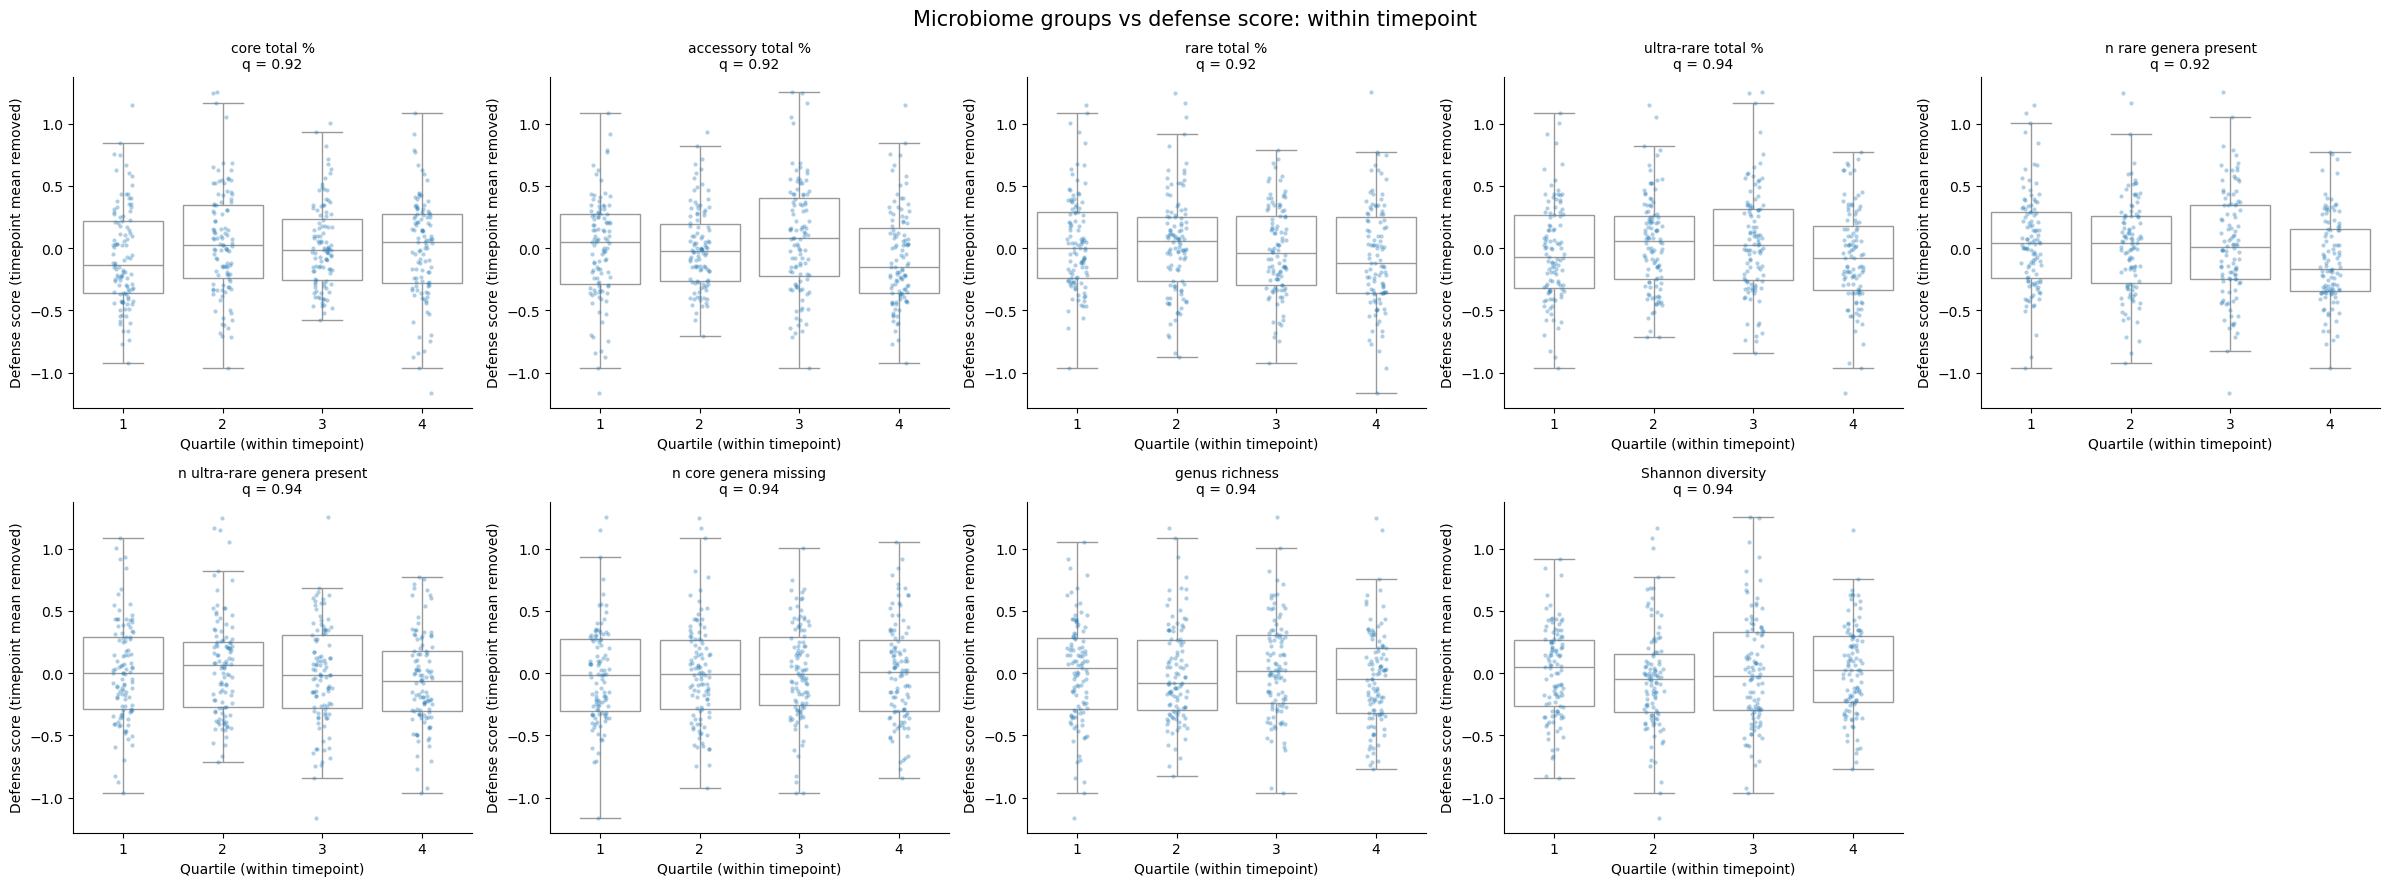

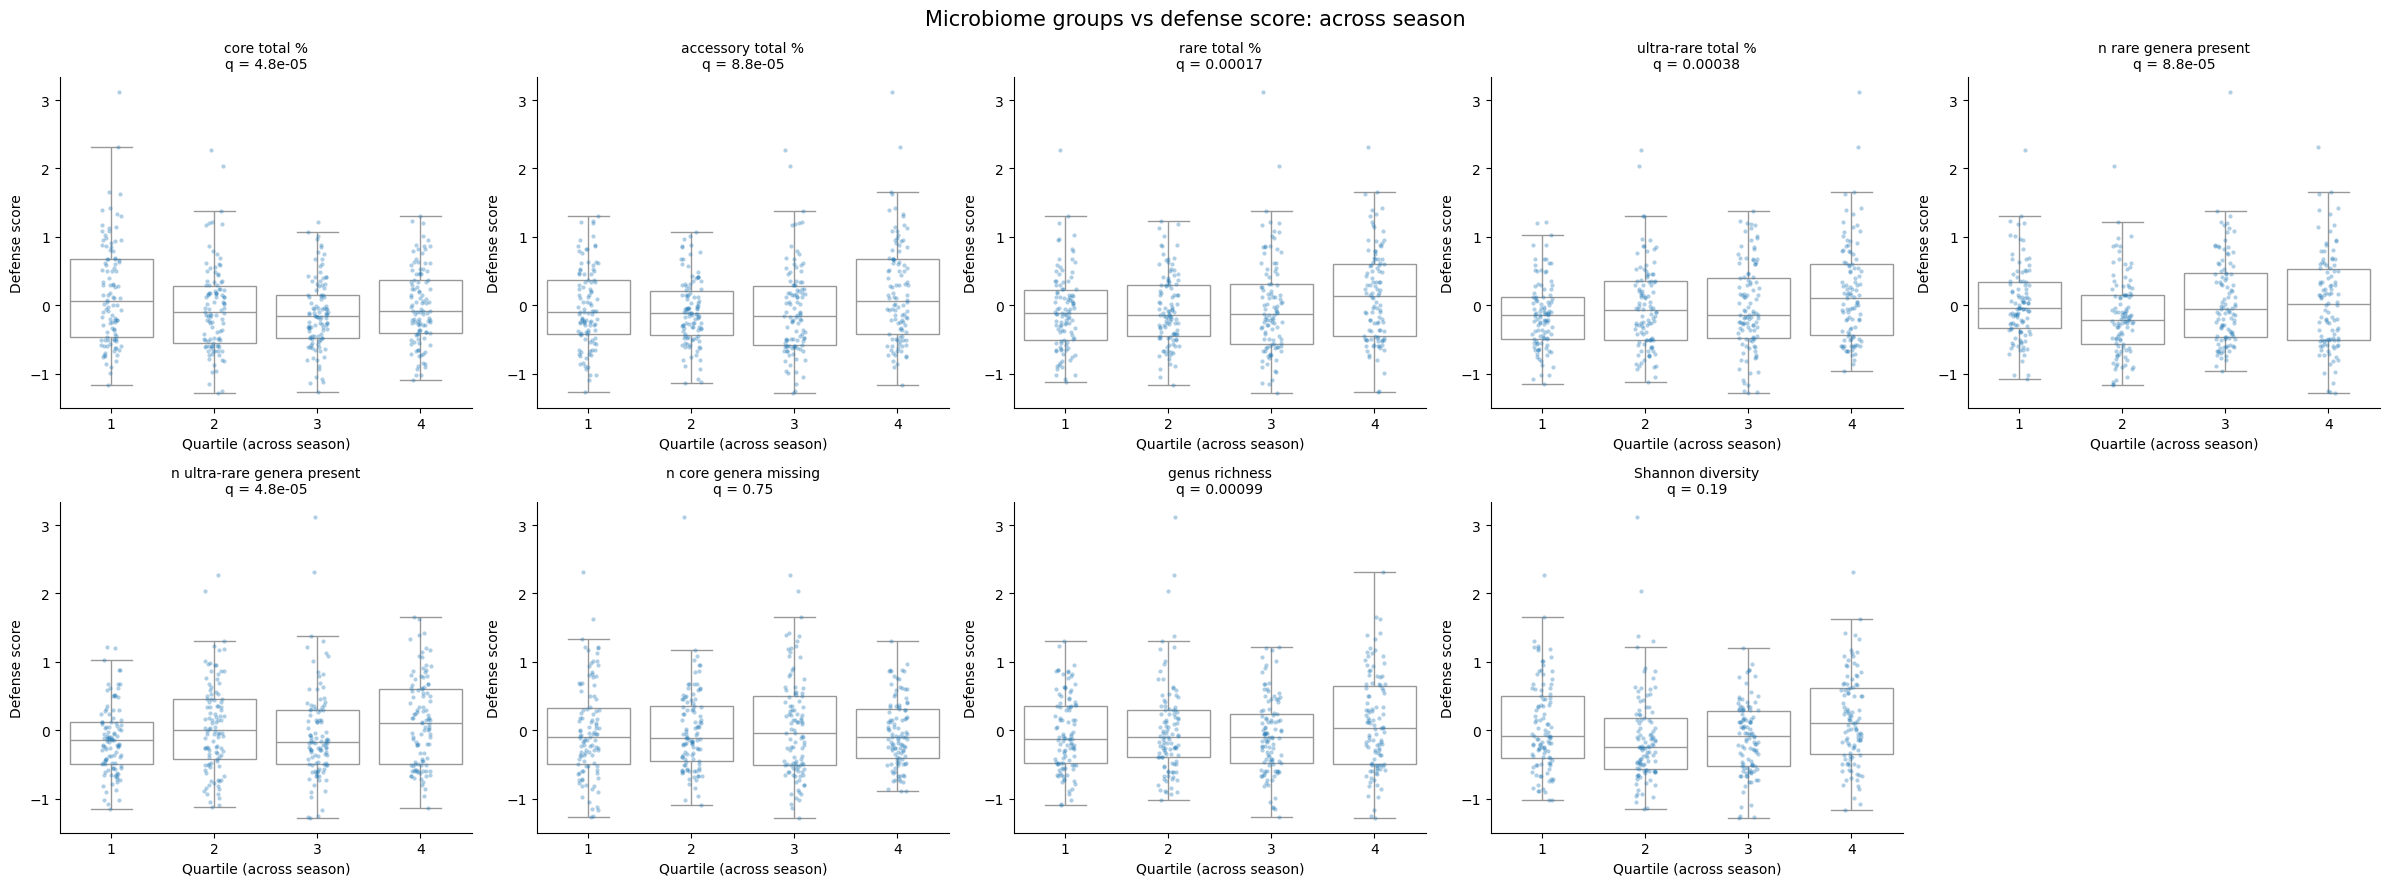

In [12]:
for mode, target in defense_versions.items():
    fig, axes = plt.subplots(2, 5, figsize=(24, 9))
    fig.patch.set_facecolor("white")
    for ax, (name, values) in zip(axes.flatten(), group_features.items()):
        if mode == "within timepoint":
            quartile = values.groupby(timepoints).transform(
                lambda v: pd.qcut(v.rank(method="first"), 4, labels=False) if v.nunique() > 1 else 0
            )
        else:
            quartile = pd.qcut(values.rank(method="first"), 4, labels=False)
        plot_df = pd.DataFrame({"quartile": (quartile + 1).astype(int), "defense": target})
        sns.boxplot(data=plot_df, x="quartile", y="defense", color="white", ax=ax, fliersize=0)
        sns.stripplot(data=plot_df, x="quartile", y="defense", alpha=0.35, size=3, ax=ax)
        q_value = group_results.loc[name, f"q ({mode})"]
        ax.set_title(f"{name}\nq = {q_value:.2g}", fontsize=10)
        ax.set_xlabel(f"Quartile ({mode})")
        ax.set_ylabel("Defense score" + (" (timepoint mean removed)" if mode == "within timepoint" else ""))
        sns.despine(ax=ax)
    axes.flatten()[-1].axis("off")
    fig.suptitle(f"Microbiome groups vs defense score: {mode}", fontsize=15)
    plt.tight_layout()
    plt.show()

### 2. Single genera

In [13]:
# Presence vs absence (genera where both groups have at least min_group_size samples)
presence_genera = present.columns[
    (present.sum() >= min_group_size) & ((~present).sum() >= min_group_size)
]
presence_rows = []
for genus in presence_genera:
    row = test_feature(present[genus])
    row.update(
        {
            "genus": genus,
            "class": genus_class[genus],
            "prevalence": present[genus].mean(),
            "mean defense, timepoint mean removed (present)": within_residual[present[genus]].mean(),
            "mean defense, timepoint mean removed (absent)": within_residual[~present[genus]].mean(),
        }
    )
    presence_rows.append(row)
presence_results = add_q(pd.DataFrame(presence_rows).set_index("genus"))

# Relative abundance, untransformed (% of reads) and log10(% + pseudocount), for genera present in enough samples
abundance_genera = present.columns[present.mean() >= min_prevalence_abundance_test]
abundance_versions = {
    "Relative abundance": sample_genera[abundance_genera],
    "Log relative abundance": np.log10(sample_genera[abundance_genera] + genus_pseudocount),
}
abundance_results_by_version = {}
for version, values in abundance_versions.items():
    rows = []
    for genus in abundance_genera:
        row = test_feature((values[genus] - values[genus].mean()) / values[genus].std())
        row.update({"genus": genus, "class": genus_class[genus], "prevalence": present[genus].mean()})
        rows.append(row)
    abundance_results_by_version[version] = add_q(pd.DataFrame(rows).set_index("genus"))
abundance_results = abundance_results_by_version["Relative abundance"]
log_abundance_results = abundance_results_by_version["Log relative abundance"]

for label, results in [("Presence/absence", presence_results), ("Relative abundance", abundance_results), ("Log relative abundance", log_abundance_results)]:
    print(
        f"{label}: {len(results)} genera tested; q < 0.05 within timepoint: "
        f"{(results['q (within timepoint)'] < 0.05).sum()}, across season: {(results['q (across season)'] < 0.05).sum()}"
    )
presence_results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_presence{csv_suffix}.csv")
abundance_results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_abundance{csv_suffix}.csv")
log_abundance_results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_log_abundance{csv_suffix}.csv")

Presence/absence: 144 genera tested; q < 0.05 within timepoint: 8, across season: 50
Relative abundance: 89 genera tested; q < 0.05 within timepoint: 10, across season: 34
Log relative abundance: 89 genera tested; q < 0.05 within timepoint: 17, across season: 47


In [14]:
show_columns = ["class", "prevalence", "coef (within timepoint)", "q (within timepoint)", "coef (across season)", "q (across season)"]
for mode in ["within timepoint", "across season"]:
    print(f"Presence/absence: top 15 by p ({mode})")
    display(presence_results.sort_values(f"p ({mode})")[show_columns].head(15).round(4))
    for version, results in abundance_results_by_version.items():
        print(f"{version}: top 15 by p ({mode})")
        display(results.sort_values(f"p ({mode})")[show_columns].head(15).round(4))

Presence/absence: top 15 by p (within timepoint)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Caldora,core,0.8066,-0.2844,0.0001,-0.3225,0.0004
g__Microcoleus,accessory,0.3892,-0.2294,0.0002,-0.1937,0.0087
g__Polaromonas,accessory,0.2052,-0.2362,0.0011,-0.4497,0.0000
g__Pseudorhodoferax,rare,0.0991,-0.2830,0.0033,-0.3283,0.0068
g__Aldersonia,accessory,0.3396,0.1721,0.0033,0.1539,0.0489
g__Chioneia,accessory,0.3467,-0.1733,0.0112,-0.3814,0.0000
g__Methylophilus,accessory,0.2476,-0.1633,0.0206,-0.1269,0.1326
g__Pigmentiphaga,accessory,0.5259,0.1425,0.0460,-0.1916,0.0082
g__Bosea,accessory,0.4811,-0.1220,0.1074,-0.1100,0.1326


Relative abundance: top 15 by p (within timepoint)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Kordiimonas,core,1.0000,-0.1304,0.0000,-0.1740,0.0000
g__Methylophilus,accessory,0.2476,-0.0969,0.0003,-0.0834,0.0171
g__Pseudomonas,core,1.0000,0.0948,0.0004,0.0947,0.0059
g__Patulibacter,core,0.8538,-0.0873,0.0054,-0.1253,0.0002
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0893,0.0054,-0.2267,0.0000
g__Aldersonia,accessory,0.3396,0.0725,0.0133,0.0419,0.2884
g__Polaromonas,accessory,0.2052,-0.0697,0.0254,-0.1250,0.0002
g__Pigmentiphaga,accessory,0.5259,0.0654,0.0463,-0.0280,0.5271
g__Nakamurella,core,0.9552,0.0609,0.0495,0.0633,0.0818


Log relative abundance: top 15 by p (within timepoint)


...

,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Allorhizobium,accessory,0.0802,0.0210,0.9535,0.7158,0.0000
g__Polaromonas,accessory,0.2052,-0.2362,0.0011,-0.4497,0.0000
g__Chioneia,accessory,0.3467,-0.1733,0.0112,-0.3814,0.0000
g__Aetherobacter,accessory,0.6840,0.0796,0.5484,-0.3549,0.0000
g__Curtobacterium,accessory,0.4646,-0.0241,0.8995,0.3183,0.0000
g__Belnapia,accessory,0.2406,0.0490,0.7892,0.3663,0.0000
g__DSM-44207,accessory,0.1415,0.0083,0.9814,0.4139,0.0000
g__Baekduia,accessory,0.1462,0.0248,0.8995,0.3805,0.0002
g__Dactylopiibacterium,accessory,0.1297,-0.0348,0.8995,0.3992,0.0002


Relative abundance: top 15 by p (across season)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0893,0.0054,-0.2267,0.0
g__Microbacterium,core,0.8726,0.0207,0.7081,0.2179,0.0
g__Limnohabitans,core,0.9976,-0.0308,0.5612,-0.2162,0.0
g__Rhizobium,accessory,0.2689,0.0173,0.7673,0.1956,0.0
g__Belnapia,accessory,0.2406,0.0396,0.3924,0.1882,0.0
g__Neorhizobium,core,1.0000,0.0137,0.8161,0.1781,0.0
g__Kordiimonas,core,1.0000,-0.1304,0.0000,-0.1740,0.0
g__Curtobacterium,accessory,0.4646,0.0214,0.7043,0.1700,0.0
g__Friedmanniella,core,0.9835,0.0093,0.8842,0.1690,0.0


Log relative abundance: top 15 by p (across season)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0519,0.2935,-0.2976,0.0
g__Limnohabitans,core,0.9976,-0.0066,0.9579,-0.2708,0.0
g__Kordiimonas,core,1.0000,-0.1749,0.0000,-0.2648,0.0
g__Microbacterium,core,0.8726,0.0773,0.0266,0.2451,0.0
g__Curtobacterium,accessory,0.4646,-0.0014,0.9639,0.2327,0.0
g__Friedmanniella,core,0.9835,0.0204,0.6601,0.1893,0.0
g__Flavobacterium,core,1.0000,-0.0173,0.6974,-0.1860,0.0
g__Belnapia,accessory,0.2406,0.0319,0.4394,0.1815,0.0
g__Chioneia,accessory,0.3467,-0.0831,0.0062,-0.1786,0.0


**Reading the volcano plots:** in the across-season row every feature is standardised and nothing else is in the model, so a feature's effect size alone fixes its p-value (both come from the same correlation with defense, with the same number of samples). The points therefore fall on a single V-shaped curve. That's expected and isn't a sign of a problem. In the within-timepoint row, the timepoint adjustment removes a different amount of each feature's variation, so points scatter around the curve.

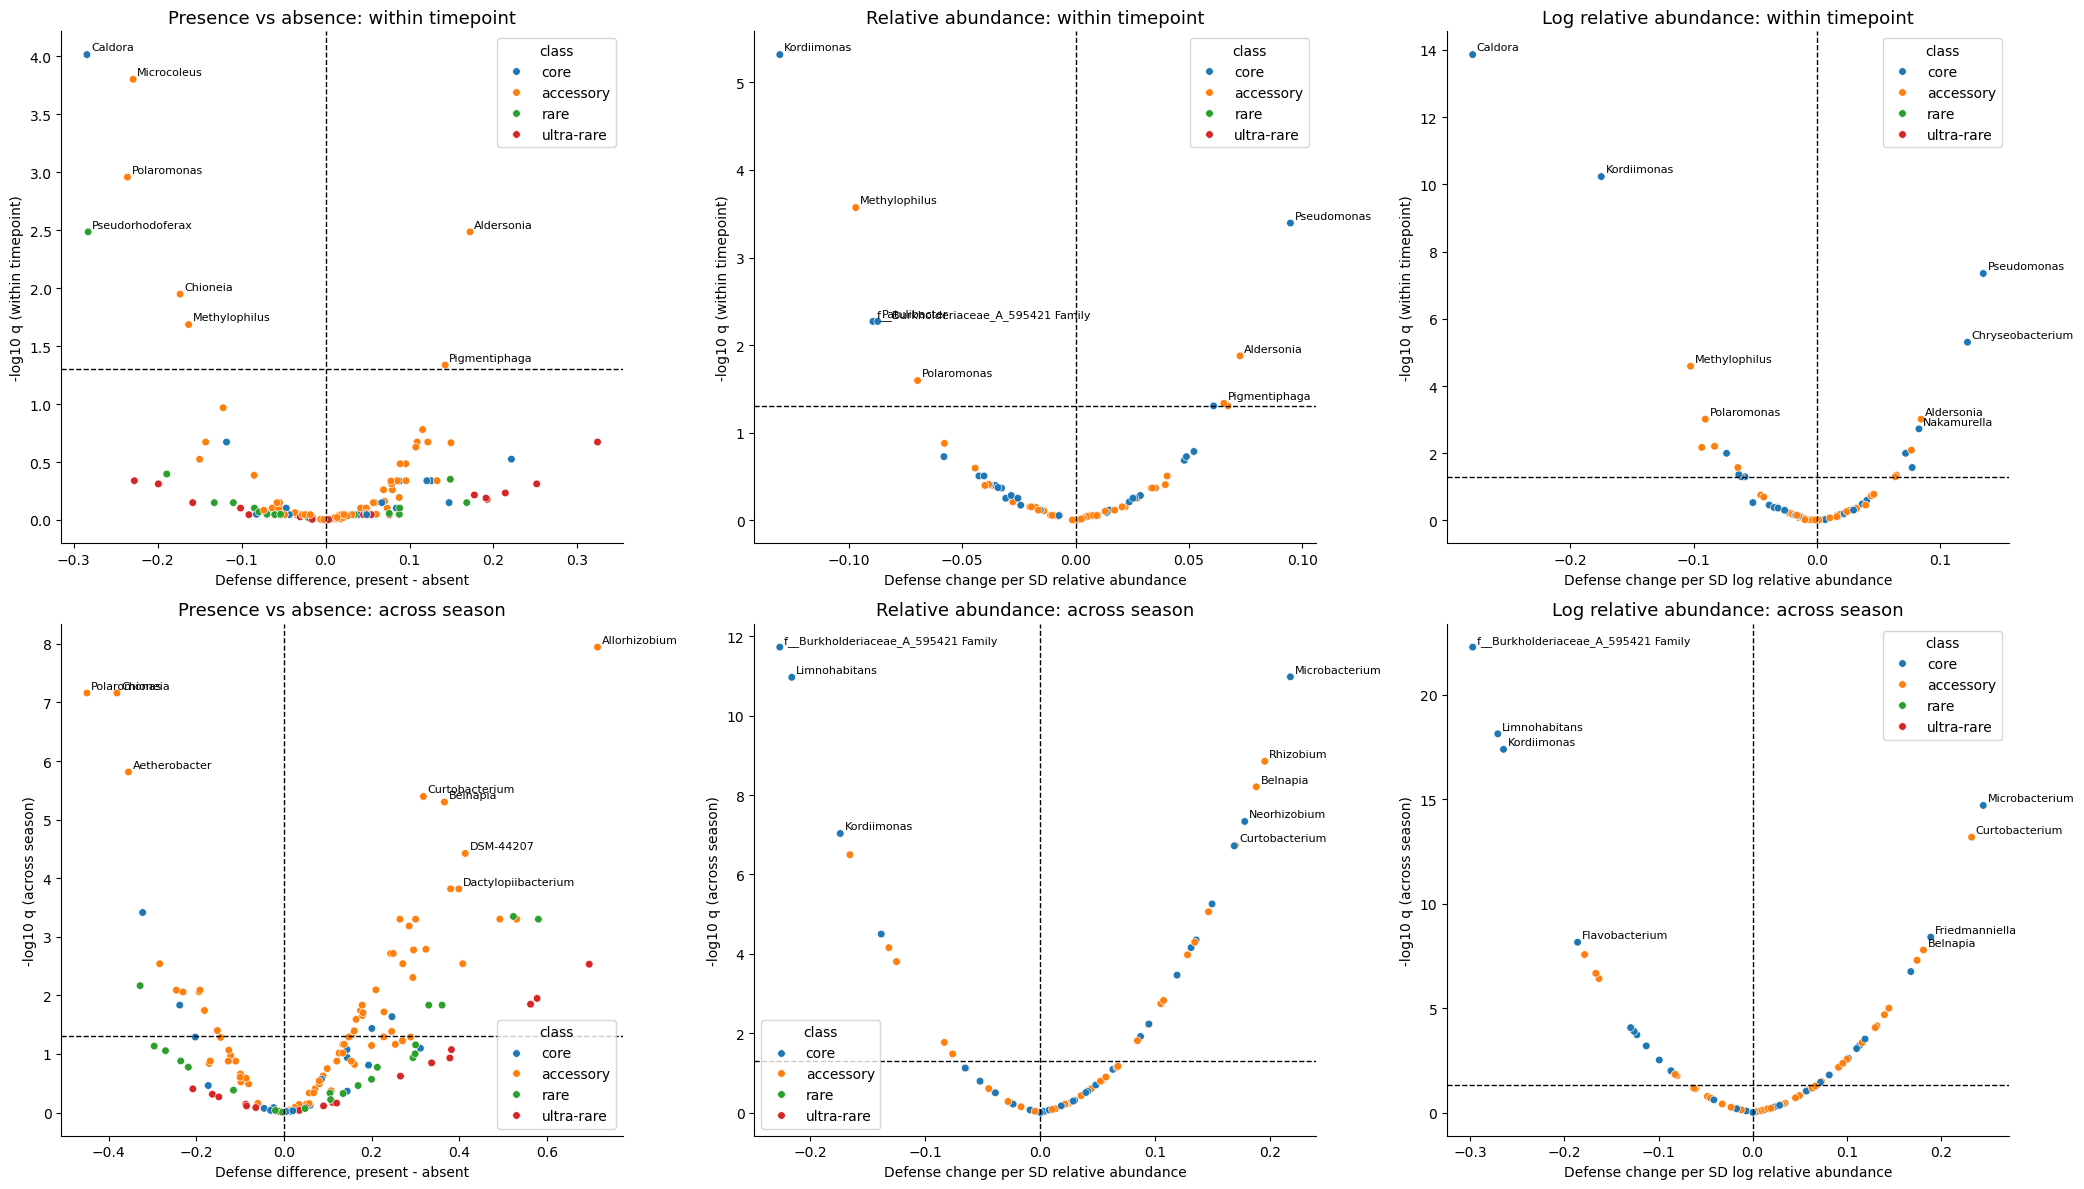

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(21, 12))
fig.patch.set_facecolor("white")
for row, mode in enumerate(["within timepoint", "across season"]):
    for col, (label, results, effect_label) in enumerate(
        [
            ("Presence vs absence", presence_results, "Defense difference, present - absent"),
            ("Relative abundance", abundance_results, "Defense change per SD relative abundance"),
            ("Log relative abundance", log_abundance_results, "Defense change per SD log relative abundance"),
        ]
    ):
        ax = axes[row, col]
        plot_df = results.assign(neg_log10_q=-np.log10(results[f"q ({mode})"].clip(lower=1e-300)))
        sns.scatterplot(
            data=plot_df,
            x=f"coef ({mode})",
            y="neg_log10_q",
            hue="class",
            hue_order=["core", "accessory", "rare", "ultra-rare"],
            s=30,
            ax=ax,
        )
        ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=1)
        ax.axvline(0, linestyle="--", color="black", linewidth=1)
        for genus, point in plot_df.sort_values("neg_log10_q", ascending=False).head(8).iterrows():
            ax.annotate(genus.replace("g__", ""), (point[f"coef ({mode})"], point["neg_log10_q"]), fontsize=8,
                        xytext=(3, 3), textcoords="offset points")
        ax.set_title(f"{label}: {mode}", fontsize=13)
        ax.set_xlabel(effect_label)
        ax.set_ylabel(f"-log10 q ({mode})")
        sns.despine(ax=ax)
plt.tight_layout()

In [16]:
# How the untransformed and log-transformed abundance results compare
comparison = pd.DataFrame(
    {
        f"t, {version} ({mode})": results[f"t ({mode})"]
        for version, results in abundance_results_by_version.items()
        for mode in ["within timepoint", "across season"]
    }
)
comparison["t, presence/absence (within timepoint)"] = presence_results["t (within timepoint)"].reindex(comparison.index)
print("Correlation of genus t-values between versions:")
display(comparison.corr().round(2))
for mode in ["within timepoint", "across season"]:
    sig = {
        version: set(results.index[results[f"q ({mode})"] < 0.05])
        for version, results in abundance_results_by_version.items()
    }
    print(
        f"{mode}: significant with untransformed only: {sorted(sig['Relative abundance'] - sig['Log relative abundance'])}; "
        f"log only: {sorted(sig['Log relative abundance'] - sig['Relative abundance'])}; "
        f"both: {sorted(sig['Relative abundance'] & sig['Log relative abundance'])}"
    )

Correlation of genus t-values between versions:


,"t, Relative abundance (within timepoint)","t, Relative abundance (across season)","t, Log relative abundance (within timepoint)","t, Log relative abundance (across season)","t, presence/absence (within timepoint)"
"t, Relative abundance (within timepoint)",1.00,0.49,0.88,0.50,0.68
"t, Relative abundance (across season)",0.49,1.00,0.38,0.95,0.20
"t, Log relative abundance (within timepoint)",0.88,0.38,1.00,0.46,0.86
"t, Log relative abundance (across season)",0.50,0.95,0.46,1.00,0.30
"t, presence/absence (within timepoint)",0.68,0.20,0.86,0.30,1.00


within timepoint: significant with untransformed only: ['f__Burkholderiaceae_A_595421 Family', 'g__Patulibacter']; log only: ['g__Brevundimonas', 'g__Caldora', 'g__Chioneia', 'g__Chryseobacterium', 'g__Klenkia', 'g__Microbacterium', 'g__Microcoleus', 'g__Pseudoduganella', 'g__Ramlibacter']; both: ['g__Abditibacterium', 'g__Aldersonia', 'g__Kordiimonas', 'g__Methylophilus', 'g__Nakamurella', 'g__Pigmentiphaga', 'g__Polaromonas', 'g__Pseudomonas']
across season: significant with untransformed only: ['g__Solirubrobacter']; log only: ['g__Aetherobacter', 'g__Brevundimonas', 'g__Caldora', 'g__Curvibacter', 'g__Herbiconiux', 'g__Herminiimonas', 'g__Hylemonella', 'g__Janthinobacterium', 'g__Massilia', 'g__Nakamurella', 'g__Pelomonas', 'g__Rhodoferax', 'g__Rugamonas', 'g__Variovorax']; both: ['f__Burkholderiaceae_A_595421 Family', 'g__Aeromicrobium', 'g__Alsobacter', 'g__Amnibacterium', 'g__Belnapia', 'g__Blastococcus', 'g__Caulobacter', 'g__Chioneia', 'g__Chryseobacterium', 'g__Curtobacterium

### 3. Pairs of genera (co-presence)

For genera present in 10–90% of samples, test samples where **both** genera are present against all other samples. For context, each pair is shown with the single-genus presence effects of its two members. A pair is only interesting if it separates defense more than either genus alone.

In [17]:
pair_genera = present.columns[
    (present.mean() >= pair_prevalence_range[0]) & (present.mean() <= pair_prevalence_range[1])
]
pair_rows = []
for genus_a, genus_b in itertools.combinations(pair_genera, 2):
    both = present[genus_a] & present[genus_b]
    if both.sum() < min_group_size or (~both).sum() < min_group_size:
        continue
    row = test_feature(both)
    row.update({"genus A": genus_a, "genus B": genus_b, "n both present": int(both.sum())})
    pair_rows.append(row)
pair_results = add_q(pd.DataFrame(pair_rows))

for mode in ["within timepoint", "across season"]:
    single_t = presence_results[f"t ({mode})"]
    pair_results[f"t genus A alone ({mode})"] = pair_results["genus A"].map(single_t)
    pair_results[f"t genus B alone ({mode})"] = pair_results["genus B"].map(single_t)
    pair_results[f"beats both singles ({mode})"] = (
        pair_results[f"t ({mode})"].abs()
        > pair_results[[f"t genus A alone ({mode})", f"t genus B alone ({mode})"]].abs().max(axis=1)
    )
pair_results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_pairs{csv_suffix}.csv", index=False)
print(
    f"Pairs tested: {len(pair_results)} (from {len(pair_genera)} genera); q < 0.05 within timepoint: "
    f"{(pair_results['q (within timepoint)'] < 0.05).sum()}, across season: {(pair_results['q (across season)'] < 0.05).sum()}"
)
for mode in ["within timepoint", "across season"]:
    better = (pair_results[f"q ({mode})"] < 0.05) & pair_results[f"beats both singles ({mode})"]
    print(f"Significant pairs ({mode}) that separate defense more than either genus alone: {better.sum()}")
    display(
        pair_results.sort_values(f"p ({mode})").head(15)[
            ["genus A", "genus B", "n both present", f"coef ({mode})", f"q ({mode})", f"t ({mode})",
             f"t genus A alone ({mode})", f"t genus B alone ({mode})", f"beats both singles ({mode})"]
        ].round(4)
    )

Pairs tested: 3394 (from 84 genera); q < 0.05 within timepoint: 92, across season: 1306
Significant pairs (within timepoint) that separate defense more than either genus alone: 33


,genus A,genus B,n both present,coef (within timepoint),q (within timepoint),t (within timepoint),t genus A alone (within timepoint),t genus B alone (within timepoint),beats both singles (within timepoint)
1476,g__Caldora,g__Microcoleus,151,-0.2715,0.0002,-5.5422,-5.0579,-4.8115,True
535,g__Aldersonia,g__Pigmentiphaga,88,0.2734,0.0004,5.2834,3.9021,3.0375,True
2870,g__Methylophilus,g__Polaromonas,37,-0.3722,0.0013,-4.9530,-3.3167,-4.2895,True
497,g__Aldersonia,g__Curvibacter,63,0.2941,0.0016,4.8377,3.9021,2.3270,True
524,g__Aldersonia,g__Microbacterium,133,0.2103,0.0024,4.6595,3.9021,1.6821,True
2973,g__Microcoleus,g__Tibeticola,122,-0.2379,0.0024,-4.6421,-4.8115,1.6597,False
1287,g__Brevundimonas,g__Microcoleus,147,-0.2230,0.0024,-4.6301,-0.5059,-4.8115,False
1473,g__Caldora,g__Methylophilus,87,-0.2402,0.0024,-4.6038,-5.0579,-3.3167,False
541,g__Aldersonia,g__Rathayibacter,104,0.2216,0.0026,4.5456,3.9021,1.6222,True
1488,g__Caldora,g__Pseudoduganella,253,-0.2024,0.0026,-4.5150,-5.0579,-2.3106,False


Significant pairs (across season) that separate defense more than either genus alone: 492


,genus A,genus B,n both present,coef (across season),q (across season),t (across season),t genus A alone (across season),t genus B alone (across season),beats both singles (across season)
1445,g__Caldora,g__Chioneia,121,-0.4458,0.0,-6.9373,-4.2465,-6.1887,True
334,g__Aetherobacter,g__Brevundimonas,250,-0.4044,0.0,-6.8455,-5.5822,-2.9292,True
1735,g__Curtobacterium,g__Rhizobium,73,0.5183,0.0,6.7214,5.3565,3.6692,True
1256,g__Brevundimonas,g__Chioneia,134,-0.4171,0.0,-6.6550,-2.9292,-6.1887,True
999,g__Belnapia,g__Herbiconiux,38,0.6667,0.0,6.5233,5.2783,4.0726,True
988,g__Belnapia,g__Curtobacterium,69,0.5058,0.0,6.3828,5.2783,5.3565,True
2286,g__Herbiconiux,g__Rhizobium,33,0.6936,0.0,6.3505,4.0726,3.6692,True
1603,g__Chioneia,g__Patulibacter,133,-0.3992,0.0,-6.3285,-6.1887,-2.3498,True
636,g__Amnibacterium,g__Belnapia,85,0.4623,0.0,6.3223,2.8196,5.2783,True
1618,g__Chioneia,g__Rhodopseudomonas,118,-0.4124,0.0,-6.3127,-6.1887,-1.4137,True


### 4. Combinations, data-driven: decision tree and random forest

Features: relative abundance (% of reads) of genera present in ≥ 10% of samples, plus the group features from section 1. Tree splits are therefore thresholds in % of reads.

Targets: the defense score with timepoint means removed (within timepoint), and the raw defense score (across season).

Models are evaluated with cross-validation that holds out whole timepoints (`GroupKFold`): the model always predicts samples from timepoints it hasn't seen. They're compared with the same models fitted to shuffled defense scores (`n_permutations`), shuffled within timepoint for the within-timepoint target and across all samples for the across-season target. If the real cross-validated R² isn't above the shuffled ones, the microbiome doesn't predict defense beyond chance.

In [18]:
model_genera = present.columns[present.mean() >= 0.1]
model_features = pd.concat([sample_genera[model_genera], group_features], axis=1)
model_features.columns = [str(c) for c in model_features.columns]
group_kfold = GroupKFold(n_splits=6)
rng = np.random.default_rng(random_seed)


def cv_r2(model, target):
    predicted = cross_val_predict(model, model_features, target, cv=group_kfold, groups=timepoints)
    return r2_score(target, predicted)


def shuffle_target(target, mode):
    if mode == "within timepoint":
        return target.groupby(timepoints).transform(lambda v: rng.permutation(v.to_numpy()))
    return pd.Series(rng.permutation(target.to_numpy()), index=target.index)


models = {
    "Decision tree (depth 3)": lambda: DecisionTreeRegressor(max_depth=3, min_samples_leaf=15, random_state=random_seed),
    "Random forest": lambda: RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, max_features=0.3, n_jobs=-1, random_state=random_seed
    ),
}
targets = defense_versions

cv_rows = []
null_r2 = {}
for model_name, make_model in models.items():
    for target_name, target in targets.items():
        real = cv_r2(make_model(), target)
        n_perm = n_permutations if "tree" in model_name.lower() else max(20, n_permutations // 5)
        null = np.array([cv_r2(make_model(), shuffle_target(target, target_name)) for _ in range(n_perm)])
        null_r2[(model_name, target_name)] = null
        cv_rows.append(
            {
                "model": model_name,
                "target": target_name,
                "cross-validated R2": real,
                "shuffled R2 (median)": np.median(null),
                "shuffled R2 (95th pct)": np.percentile(null, 95),
                "permutation p": (1 + (null >= real).sum()) / (1 + len(null)),
                "permutations": len(null),
            }
        )
cv_results = pd.DataFrame(cv_rows)
cv_results.round(3)

,model,target,cross-validated R2,shuffled R2 (median),shuffled R2 (95th pct),permutation p,permutations
0,Decision tree (depth 3),within timepoint,0.020,-0.152,-0.072,0.010,100
1,Decision tree (depth 3),across season,0.237,-0.151,-0.077,0.010,100
2,Random forest,within timepoint,0.162,-0.020,0.002,0.048,20
3,Random forest,across season,0.383,-0.034,0.002,0.048,20


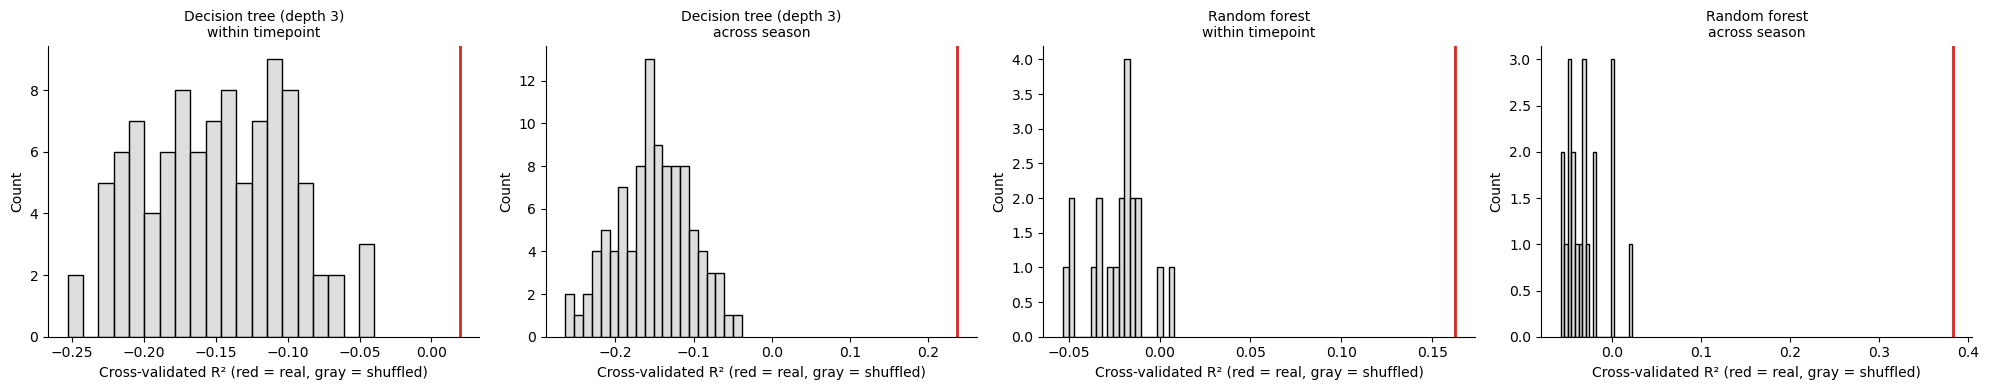

In [19]:
fig, axes = plt.subplots(1, len(null_r2), figsize=(5 * len(null_r2), 4))
fig.patch.set_facecolor("white")
for ax, ((model_name, target_name), null) in zip(axes, null_r2.items()):
    real = cv_results.loc[
        (cv_results["model"] == model_name) & (cv_results["target"] == target_name), "cross-validated R2"
    ].iloc[0]
    sns.histplot(null, bins=20, color="lightgray", ax=ax)
    ax.axvline(real, color="tab:red", linewidth=2)
    ax.set_title(f"{model_name}\n{target_name}", fontsize=10)
    ax.set_xlabel("Cross-validated R² (red = real, gray = shuffled)")
    sns.despine(ax=ax)
plt.tight_layout()

In [20]:
# Random forest feature importance (impurity importance, fitted on all samples)
importance_tables = {}
for target_name, target in targets.items():
    forest = models["Random forest"]().fit(model_features, target)
    importance_tables[target_name] = pd.Series(forest.feature_importances_, index=model_features.columns)
importance = pd.DataFrame(importance_tables).sort_values("within timepoint", ascending=False)
importance.head(20).round(4)

,within timepoint,across season
g__Caldora,0.0613,0.0216
g__Pseudomonas,0.0499,0.0392
g__Kordiimonas,0.0492,0.0764
g__Chryseobacterium,0.0479,0.0518
g__Methylophilus,0.0432,0.0038
g__Aldersonia,0.0428,0.0035
g__Ramlibacter,0.0238,0.0078
g__Klenkia,0.0214,0.0097
g__Aetherobacter,0.0203,0.0097
g__Brevundimonas,0.0201,0.0201



Tree strata (within timepoint):


,count,mean,std
leaf,,,
11,48,-0.418,0.277
4,24,-0.213,0.355
10,85,-0.082,0.352
13,37,-0.020,0.257
3,154,0.061,0.348
6,36,0.148,0.376
14,15,0.289,0.262
7,25,0.552,0.270



Tree strata (across season):


,count,mean,std
leaf,,,
6,187,-0.335,0.441
7,60,0.031,0.565
10,124,0.089,0.481
3,19,0.665,0.401
9,18,0.733,0.464
2,16,1.410,0.626


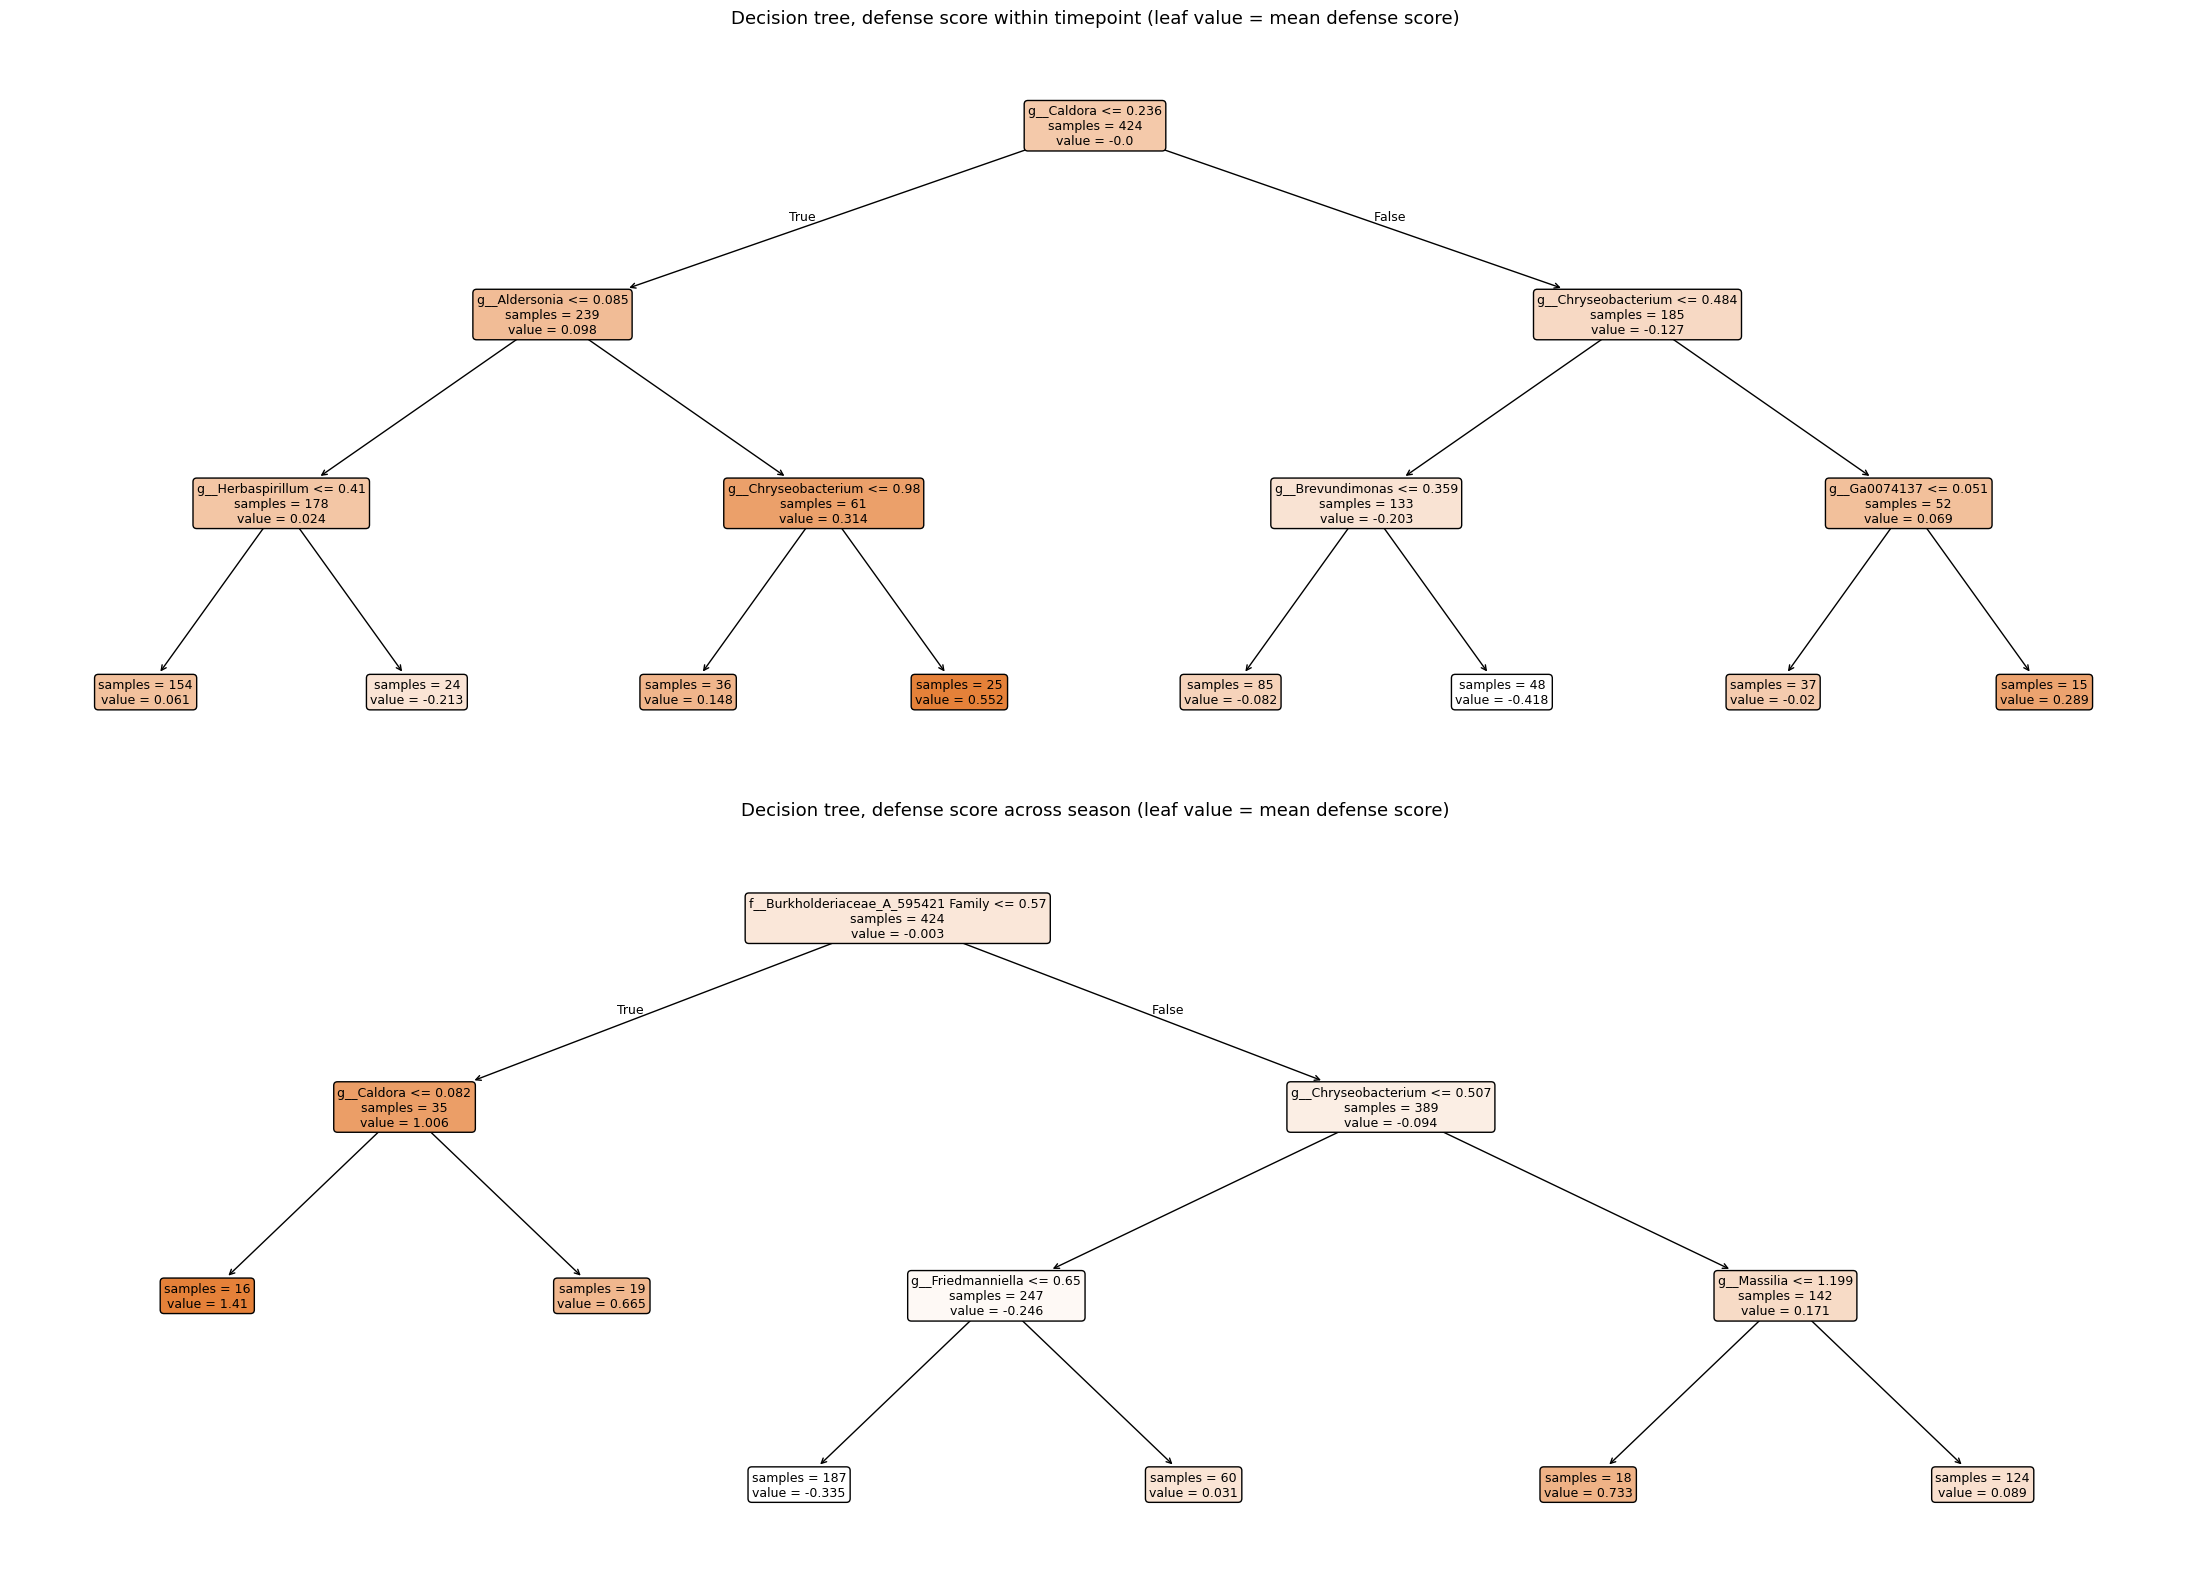

In [21]:
# The decision tree fitted on all samples: each leaf is a microbiome-defined stratum
fig, axes = plt.subplots(2, 1, figsize=(22, 16))
fig.patch.set_facecolor("white")
tree_strata = {}
for ax, (target_name, target) in zip(axes, targets.items()):
    tree = models["Decision tree (depth 3)"]().fit(model_features, target)
    plot_tree(tree, feature_names=model_features.columns, filled=True, rounded=True, fontsize=9, ax=ax, impurity=False)
    ax.set_title(f"Decision tree, defense score {target_name} (leaf value = mean defense score)", fontsize=13)
    leaves = pd.Series(tree.apply(model_features), index=samples)
    tree_strata[target_name] = (
        pd.DataFrame({"leaf": leaves, "defense": target})
        .groupby("leaf")["defense"]
        .agg(["count", "mean", "std"])
        .sort_values("mean")
    )
plt.tight_layout()
for target_name, strata in tree_strata.items():
    print(f"\nTree strata ({target_name}):")
    display(strata.round(3))

In [22]:
pass_summaries[score_label] = {
    "genes": len(gene_sets[score_label]),
    **{
        f"{test}, q < 0.05 ({mode})": int((results[f"q ({mode})"] < 0.05).sum())
        for test, results in [
            ("presence", presence_results),
            ("relative abundance", abundance_results),
            ("log relative abundance", log_abundance_results),
            ("pairs", pair_results),
        ]
        for mode in ["within timepoint", "across season"]
    },
    **{
        f"{row.model} R2 ({row.target})": round(row._3, 3)
        for row in cv_results.itertuples()
    },
    "top within-timepoint genera (log abundance)": ", ".join(
        g.replace("g__", "")
        for g in log_abundance_results.sort_values("p (within timepoint)").index[:6]
    ),
}
print("Summary saved for", score_label)

Summary saved for r > 0.5


# Defense score from genes with r > 0.3 (n genes printed below)

The full stratification analysis with this score. Results files end in `_log2_score_r0.3`.

In [23]:
score_label = "r > 0.3"
csv_suffix = "_log2_score_r0.3"
trimmed_metadata["Defense Z Score"] = defense_scores[score_label]
print(f"{score_label}: {len(gene_sets[score_label])} genes")

r > 0.3: 333 genes


### Microbiome features

In [24]:
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Sept_2026_recalled_genera/lic_16S_gen_rab_clean.csv"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]
genus_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Genus", aggfunc="sum", fill_value=0
)
genus_abundance_matrix = genus_abundance_matrix.div(genus_abundance_matrix.sum(axis=1), axis=0) * 100

seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
# Genera never seen in seasonal samples get 0% prevalence (rare and ultra-rare)
seasonal_prevalence = (genus_abundance_matrix.loc[seasonal_samples] > 0).mean().reindex(
    genus_abundance_matrix.columns, fill_value=0.0
)
genus_class = pd.Series(
    np.select(
        [
            seasonal_prevalence > core_prevalence_threshold,
            seasonal_prevalence < ultra_rare_prevalence_threshold,
            seasonal_prevalence < rare_prevalence_threshold,
        ],
        ["core", "ultra-rare", "rare"],
        default="accessory",
    ),
    index=seasonal_prevalence.index,
)
core_genera = genus_class.index[genus_class == "core"]
rare_genera = genus_class.index[genus_class.isin(["rare", "ultra-rare"])]  # all < 10%
ultra_rare_genera = genus_class.index[genus_class == "ultra-rare"]
accessory_genera = genus_class.index[genus_class == "accessory"]
print(f"Core: {len(core_genera)}, accessory: {len(accessory_genera)}, rare (< 10%): {len(rare_genera)}, "
      f"of which ultra-rare (< {ultra_rare_prevalence_threshold:.0%}): {len(ultra_rare_genera)}")

samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(genus_abundance_matrix.index)]
sample_genera = genus_abundance_matrix.loc[trimmed_metadata.loc[samples, "sampID"]].set_index(samples)
present = sample_genera > 0

group_features = pd.DataFrame(
    {
        "core total %": sample_genera[core_genera].sum(axis=1),
        "accessory total %": sample_genera[accessory_genera].sum(axis=1),
        "rare total %": sample_genera[rare_genera].sum(axis=1),
        "ultra-rare total %": sample_genera[ultra_rare_genera].sum(axis=1),
        "n rare genera present": present[rare_genera].sum(axis=1),
        "n ultra-rare genera present": present[ultra_rare_genera].sum(axis=1),
        "n core genera missing": (~present[core_genera]).sum(axis=1),
        "genus richness": present.sum(axis=1),
        "Shannon diversity": sample_genera.apply(lambda row: shannon(row.to_numpy()), axis=1),
    }
)
defense = trimmed_metadata.loc[samples, "Defense Z Score"]
timepoints = trimmed_metadata.loc[samples, "timepoint"]
timepoint_dummies = pd.get_dummies(timepoints, prefix="tp", drop_first=True, dtype=float)
print(f"Samples with transcriptome and microbiome: {len(samples)}")
group_features.describe().round(2)

Core: 36, accessory: 82, rare (< 10%): 160, of which ultra-rare (< 5%): 137
Samples with transcriptome and microbiome: 424


,core total %,accessory total %,rare total %,ultra-rare total %,n rare genera present,n ultra-rare genera present,n core genera missing,genus richness,Shannon diversity
count,424.00,424.00,424.00,424.00,424.00,424.00,424.00,424.00,424.00
mean,91.66,7.88,0.46,0.22,2.79,1.45,2.77,61.77,2.79
std,4.41,4.08,0.63,0.40,3.02,2.11,2.23,12.83,0.32
min,67.33,1.08,0.00,0.00,0.00,0.00,0.00,34.00,1.08
25%,89.59,5.03,0.07,0.00,1.00,0.00,1.00,53.00,2.61
50%,92.62,7.07,0.26,0.07,2.00,1.00,2.00,61.00,2.80
75%,94.73,9.92,0.63,0.23,4.00,2.00,4.00,69.00,2.98
max,98.92,29.92,5.22,2.97,21.00,18.00,12.00,114.00,3.76


In [25]:
def test_feature(x):
    """Coefficient of a feature on the defense score, within timepoint and across the season."""
    out = {}
    for label, covariates in [
        ("within timepoint", timepoint_dummies),
        ("across season", None),
    ]:
        X = sm.add_constant(pd.concat([covariates, x.rename("feature").astype(float)], axis=1))
        fit = sm.OLS(defense, X).fit()
        out[f"coef ({label})"] = fit.params["feature"]
        out[f"t ({label})"] = fit.tvalues["feature"]
        out[f"p ({label})"] = fit.pvalues["feature"]
    return out


def add_q(results):
    for label in ["within timepoint", "across season"]:
        results[f"q ({label})"] = multipletests(results[f"p ({label})"], method="fdr_bh")[1]
    return results


# Defense score with timepoint means removed (within timepoint), and as is (across season)
within_residual = sm.OLS(defense, sm.add_constant(timepoint_dummies)).fit().resid
defense_versions = {"within timepoint": within_residual, "across season": defense}

### 1. Microbiome groups

Each feature is tested as a continuous value; coefficients are per standard deviation of the feature. The plots split samples into quartiles of each feature: within timepoint (defense with timepoint means removed), and across the season (raw defense score).

In [26]:
group_results = pd.DataFrame(
    {name: test_feature((values - values.mean()) / values.std()) for name, values in group_features.items()}
).T
group_results = add_q(group_results)
group_results[[c for c in group_results.columns if c.startswith(("coef", "q"))]].round(4)

,coef (within timepoint),coef (across season),q (within timepoint),q (across season)
core total %,0.0463,-0.0663,0.2336,0.0279
accessory total %,-0.0448,0.0620,0.2336,0.0279
rare total %,-0.0271,0.0621,0.5318,0.0279
ultra-rare total %,-0.0188,0.0608,0.7033,0.0279
n rare genera present,-0.0289,0.0764,0.5318,0.0141
n ultra-rare genera present,-0.0143,0.0870,0.7033,0.0067
n core genera missing,-0.0174,0.0124,0.7033,0.6326
genus richness,0.0098,0.0595,0.7102,0.0279
Shannon diversity,0.0102,0.0277,0.7102,0.3226


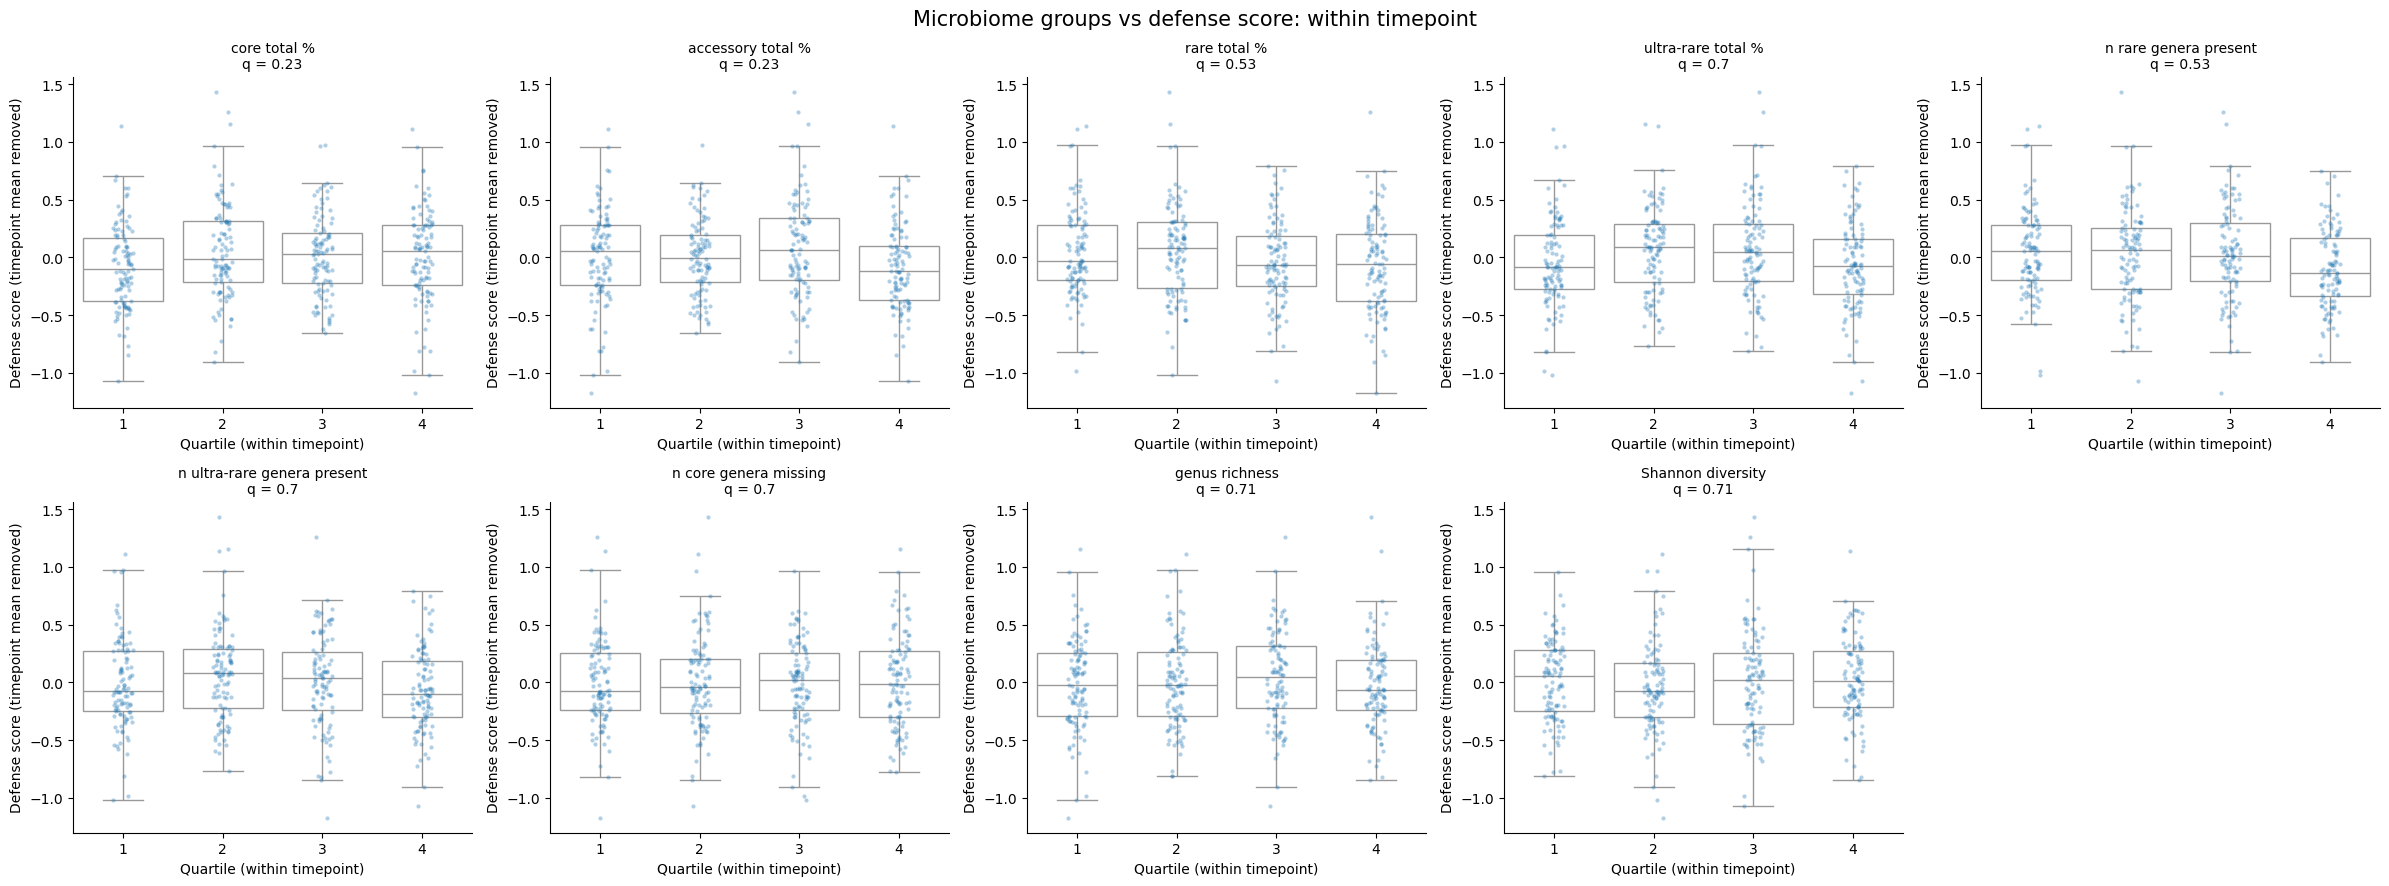

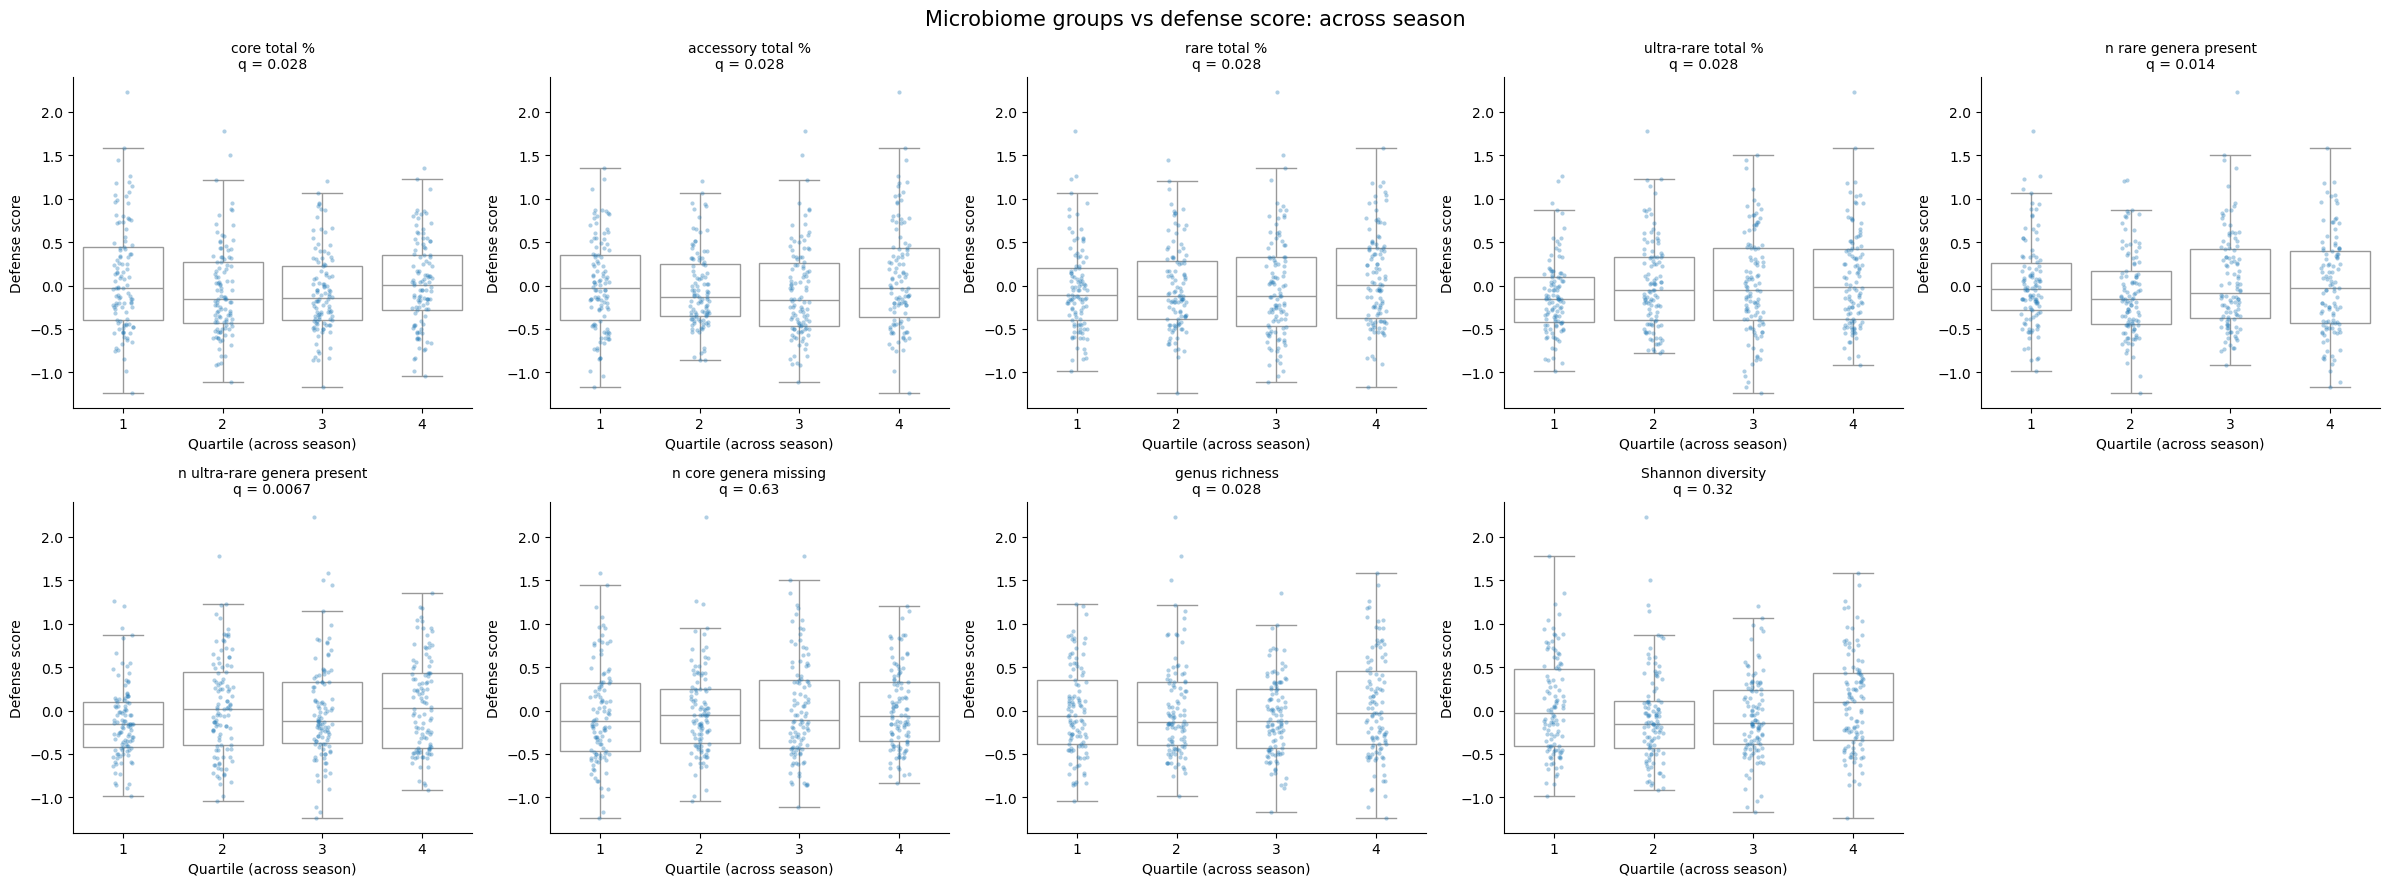

In [27]:
for mode, target in defense_versions.items():
    fig, axes = plt.subplots(2, 5, figsize=(24, 9))
    fig.patch.set_facecolor("white")
    for ax, (name, values) in zip(axes.flatten(), group_features.items()):
        if mode == "within timepoint":
            quartile = values.groupby(timepoints).transform(
                lambda v: pd.qcut(v.rank(method="first"), 4, labels=False) if v.nunique() > 1 else 0
            )
        else:
            quartile = pd.qcut(values.rank(method="first"), 4, labels=False)
        plot_df = pd.DataFrame({"quartile": (quartile + 1).astype(int), "defense": target})
        sns.boxplot(data=plot_df, x="quartile", y="defense", color="white", ax=ax, fliersize=0)
        sns.stripplot(data=plot_df, x="quartile", y="defense", alpha=0.35, size=3, ax=ax)
        q_value = group_results.loc[name, f"q ({mode})"]
        ax.set_title(f"{name}\nq = {q_value:.2g}", fontsize=10)
        ax.set_xlabel(f"Quartile ({mode})")
        ax.set_ylabel("Defense score" + (" (timepoint mean removed)" if mode == "within timepoint" else ""))
        sns.despine(ax=ax)
    axes.flatten()[-1].axis("off")
    fig.suptitle(f"Microbiome groups vs defense score: {mode}", fontsize=15)
    plt.tight_layout()
    plt.show()

### 2. Single genera

In [28]:
# Presence vs absence (genera where both groups have at least min_group_size samples)
presence_genera = present.columns[
    (present.sum() >= min_group_size) & ((~present).sum() >= min_group_size)
]
presence_rows = []
for genus in presence_genera:
    row = test_feature(present[genus])
    row.update(
        {
            "genus": genus,
            "class": genus_class[genus],
            "prevalence": present[genus].mean(),
            "mean defense, timepoint mean removed (present)": within_residual[present[genus]].mean(),
            "mean defense, timepoint mean removed (absent)": within_residual[~present[genus]].mean(),
        }
    )
    presence_rows.append(row)
presence_results = add_q(pd.DataFrame(presence_rows).set_index("genus"))

# Relative abundance, untransformed (% of reads) and log10(% + pseudocount), for genera present in enough samples
abundance_genera = present.columns[present.mean() >= min_prevalence_abundance_test]
abundance_versions = {
    "Relative abundance": sample_genera[abundance_genera],
    "Log relative abundance": np.log10(sample_genera[abundance_genera] + genus_pseudocount),
}
abundance_results_by_version = {}
for version, values in abundance_versions.items():
    rows = []
    for genus in abundance_genera:
        row = test_feature((values[genus] - values[genus].mean()) / values[genus].std())
        row.update({"genus": genus, "class": genus_class[genus], "prevalence": present[genus].mean()})
        rows.append(row)
    abundance_results_by_version[version] = add_q(pd.DataFrame(rows).set_index("genus"))
abundance_results = abundance_results_by_version["Relative abundance"]
log_abundance_results = abundance_results_by_version["Log relative abundance"]

for label, results in [("Presence/absence", presence_results), ("Relative abundance", abundance_results), ("Log relative abundance", log_abundance_results)]:
    print(
        f"{label}: {len(results)} genera tested; q < 0.05 within timepoint: "
        f"{(results['q (within timepoint)'] < 0.05).sum()}, across season: {(results['q (across season)'] < 0.05).sum()}"
    )
presence_results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_presence{csv_suffix}.csv")
abundance_results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_abundance{csv_suffix}.csv")
log_abundance_results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_log_abundance{csv_suffix}.csv")

Presence/absence: 144 genera tested; q < 0.05 within timepoint: 6, across season: 30
Relative abundance: 89 genera tested; q < 0.05 within timepoint: 9, across season: 29
Log relative abundance: 89 genera tested; q < 0.05 within timepoint: 20, across season: 37


In [29]:
show_columns = ["class", "prevalence", "coef (within timepoint)", "q (within timepoint)", "coef (across season)", "q (across season)"]
for mode in ["within timepoint", "across season"]:
    print(f"Presence/absence: top 15 by p ({mode})")
    display(presence_results.sort_values(f"p ({mode})")[show_columns].head(15).round(4))
    for version, results in abundance_results_by_version.items():
        print(f"{version}: top 15 by p ({mode})")
        display(results.sort_values(f"p ({mode})")[show_columns].head(15).round(4))

Presence/absence: top 15 by p (within timepoint)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Caldora,core,0.8066,-0.2605,0.0005,-0.2983,0.0002
g__Aldersonia,accessory,0.3396,0.1898,0.0009,0.1874,0.0118
g__Microcoleus,accessory,0.3892,-0.1837,0.0045,-0.1250,0.0739
g__Polaromonas,accessory,0.2052,-0.2098,0.0045,-0.3590,0.0000
g__Chioneia,accessory,0.3467,-0.1662,0.0177,-0.2730,0.0000
g__Pseudorhodoferax,rare,0.0991,-0.2331,0.0262,-0.2800,0.0190
g__Rhizorhabdus,accessory,0.4127,0.1349,0.0528,0.0222,0.8152
g__Pigmentiphaga,accessory,0.5259,0.1329,0.0732,-0.0853,0.2395
g__Methylophilus,accessory,0.2476,-0.1287,0.1187,-0.0981,0.2395


Relative abundance: top 15 by p (within timepoint)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Kordiimonas,core,1.0000,-0.1405,0.0000,-0.1484,0.0000
g__Aldersonia,accessory,0.3396,0.0847,0.0032,0.0664,0.0341
g__Methylophilus,accessory,0.2476,-0.0760,0.0073,-0.0656,0.0359
g__Pseudomonas,core,1.0000,0.0769,0.0073,0.0769,0.0119
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0756,0.0255,-0.1536,0.0000
g__Patulibacter,core,0.8538,-0.0728,0.0255,-0.1006,0.0005
g__Abditibacterium,accessory,0.2925,0.0732,0.0255,0.0558,0.0844
g__Nakamurella,core,0.9552,0.0619,0.0438,0.0605,0.0579
g__Chryseobacterium,core,0.9222,0.0635,0.0438,0.1015,0.0005


Log relative abundance: top 15 by p (within timepoint)


...

,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Polaromonas,accessory,0.2052,-0.2098,0.0045,-0.3590,0.0000
g__Chioneia,accessory,0.3467,-0.1662,0.0177,-0.2730,0.0000
g__Caldora,core,0.8066,-0.2605,0.0005,-0.2983,0.0002
g__Allorhizobium,accessory,0.0802,0.0287,0.9201,0.4147,0.0004
g__Belnapia,accessory,0.2406,0.0643,0.6905,0.2475,0.0011
g__Dactylopiibacterium,accessory,0.1297,-0.0355,0.8963,0.2745,0.0083
g__Aldersonia,accessory,0.3396,0.1898,0.0009,0.1874,0.0118
g__Microvirga,rare,0.0613,0.0223,0.9201,0.3580,0.0156
g__Pseudorhodoferax,rare,0.0991,-0.2331,0.0262,-0.2800,0.0190


Relative abundance: top 15 by p (across season)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0756,0.0255,-0.1536,0.0000
g__Microbacterium,core,0.8726,0.0317,0.4706,0.1490,0.0000
g__Kordiimonas,core,1.0000,-0.1405,0.0000,-0.1484,0.0000
g__Limnohabitans,core,0.9976,-0.0322,0.4832,-0.1409,0.0000
g__Rhizobium,accessory,0.2689,0.0148,0.7021,0.1282,0.0000
g__Alsobacter,accessory,0.3113,0.0324,0.4107,0.1262,0.0000
g__Belnapia,accessory,0.2406,0.0342,0.3965,0.1225,0.0000
g__Neorhizobium,core,1.0000,0.0291,0.4832,0.1208,0.0000
g__Tibeticola,accessory,0.7854,-0.0332,0.4440,-0.1073,0.0003


Log relative abundance: top 15 by p (across season)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Kordiimonas,core,1.0000,-0.1786,0.0000,-0.2139,0.0000
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0406,0.4414,-0.1873,0.0000
g__Microbacterium,core,0.8726,0.0978,0.0025,0.1815,0.0000
g__Limnohabitans,core,0.9976,-0.0017,0.9812,-0.1652,0.0000
g__Chryseobacterium,core,0.9222,0.1281,0.0000,0.1438,0.0000
g__Pseudomonas,core,1.0000,0.1159,0.0000,0.1355,0.0000
g__Curtobacterium,accessory,0.4646,-0.0018,0.9812,0.1341,0.0000
g__Flavobacterium,core,1.0000,-0.0142,0.7413,-0.1306,0.0000
g__Chioneia,accessory,0.3467,-0.0820,0.0050,-0.1290,0.0000


**Reading the volcano plots:** in the across-season row every feature is standardised and nothing else is in the model, so a feature's effect size alone fixes its p-value (both come from the same correlation with defense, with the same number of samples). The points therefore fall on a single V-shaped curve. That's expected and isn't a sign of a problem. In the within-timepoint row, the timepoint adjustment removes a different amount of each feature's variation, so points scatter around the curve.

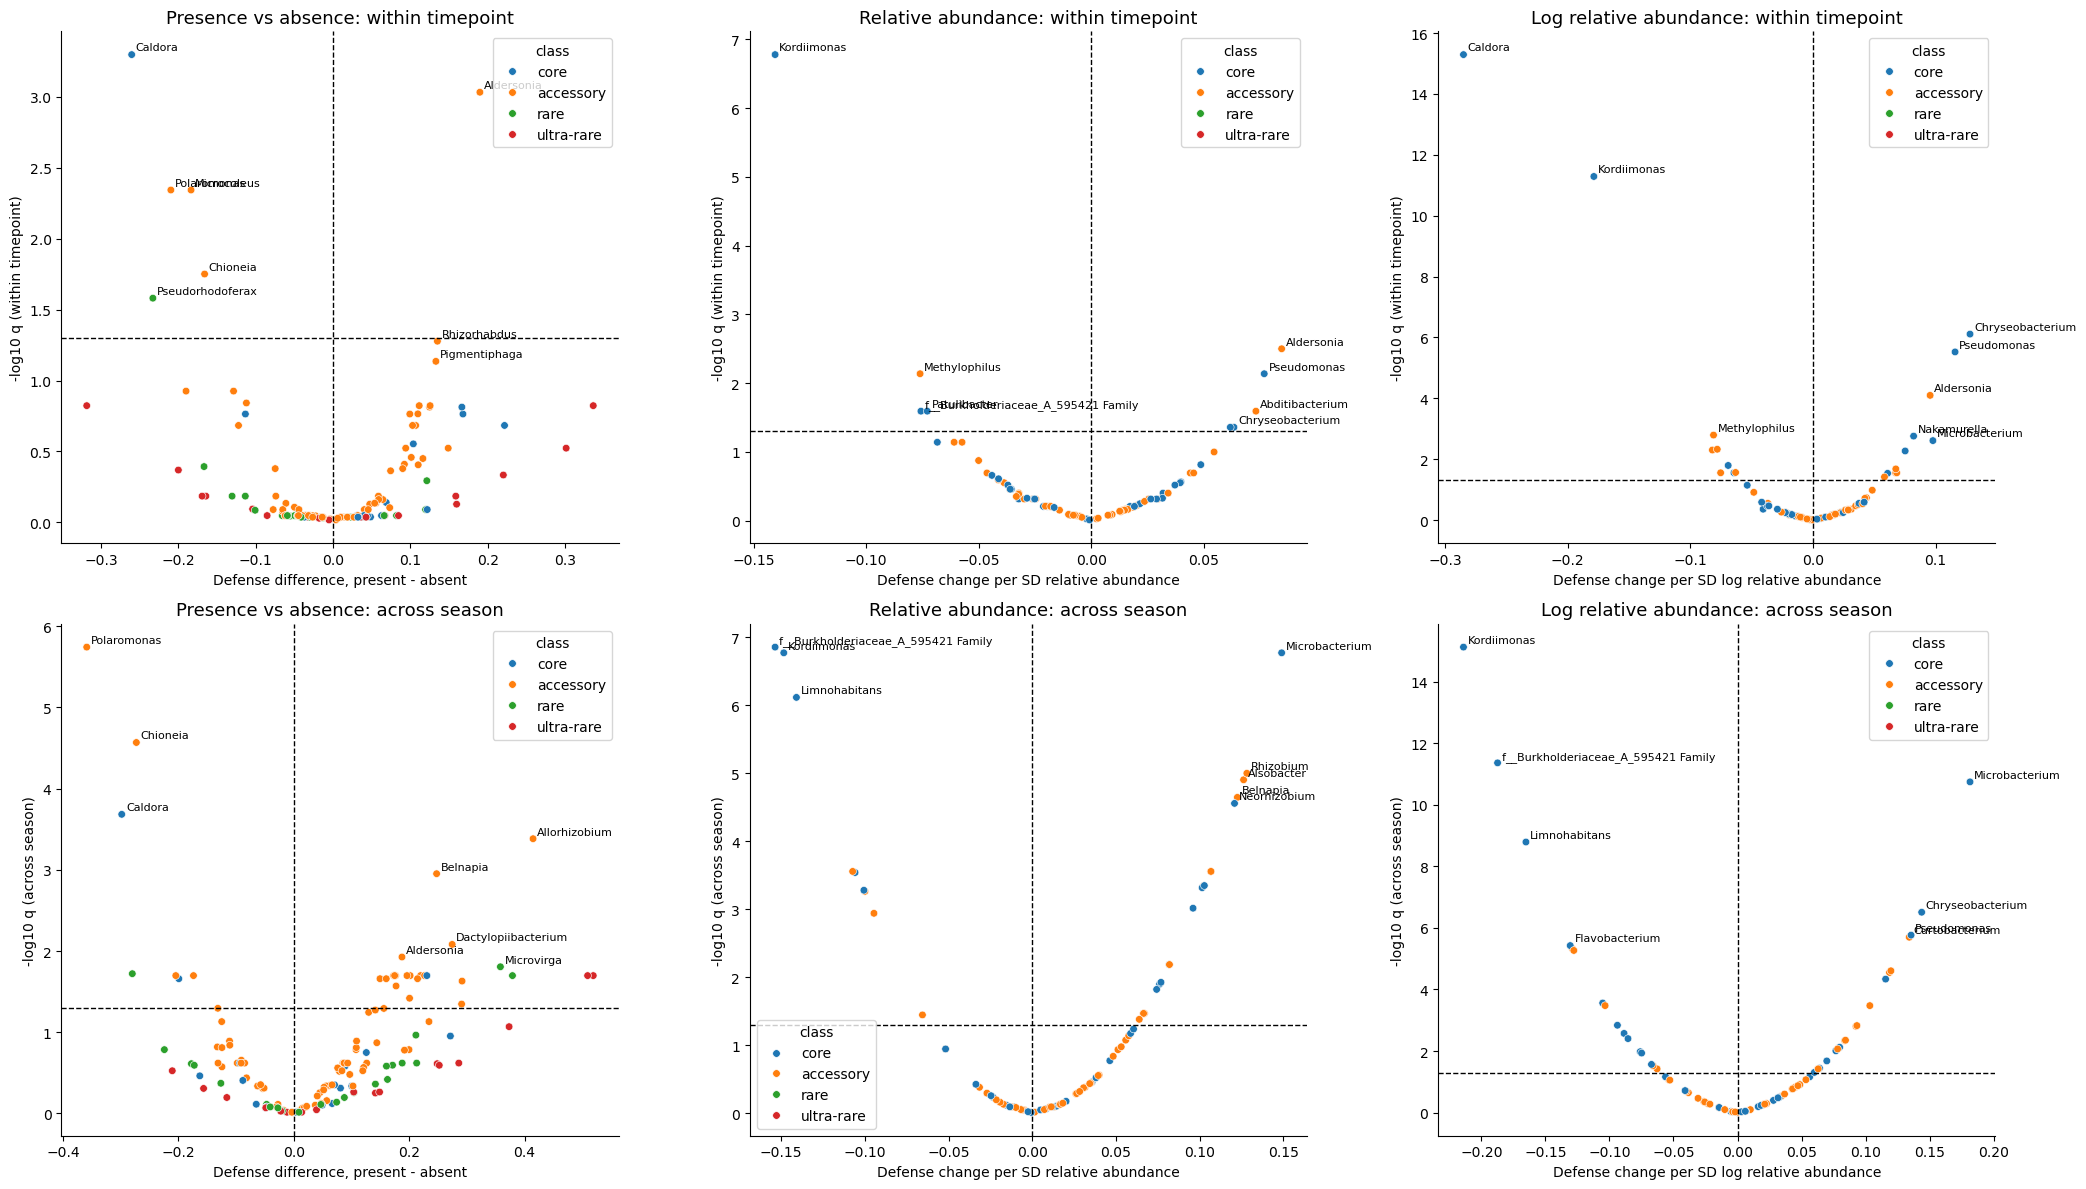

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(21, 12))
fig.patch.set_facecolor("white")
for row, mode in enumerate(["within timepoint", "across season"]):
    for col, (label, results, effect_label) in enumerate(
        [
            ("Presence vs absence", presence_results, "Defense difference, present - absent"),
            ("Relative abundance", abundance_results, "Defense change per SD relative abundance"),
            ("Log relative abundance", log_abundance_results, "Defense change per SD log relative abundance"),
        ]
    ):
        ax = axes[row, col]
        plot_df = results.assign(neg_log10_q=-np.log10(results[f"q ({mode})"].clip(lower=1e-300)))
        sns.scatterplot(
            data=plot_df,
            x=f"coef ({mode})",
            y="neg_log10_q",
            hue="class",
            hue_order=["core", "accessory", "rare", "ultra-rare"],
            s=30,
            ax=ax,
        )
        ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=1)
        ax.axvline(0, linestyle="--", color="black", linewidth=1)
        for genus, point in plot_df.sort_values("neg_log10_q", ascending=False).head(8).iterrows():
            ax.annotate(genus.replace("g__", ""), (point[f"coef ({mode})"], point["neg_log10_q"]), fontsize=8,
                        xytext=(3, 3), textcoords="offset points")
        ax.set_title(f"{label}: {mode}", fontsize=13)
        ax.set_xlabel(effect_label)
        ax.set_ylabel(f"-log10 q ({mode})")
        sns.despine(ax=ax)
plt.tight_layout()

In [31]:
# How the untransformed and log-transformed abundance results compare
comparison = pd.DataFrame(
    {
        f"t, {version} ({mode})": results[f"t ({mode})"]
        for version, results in abundance_results_by_version.items()
        for mode in ["within timepoint", "across season"]
    }
)
comparison["t, presence/absence (within timepoint)"] = presence_results["t (within timepoint)"].reindex(comparison.index)
print("Correlation of genus t-values between versions:")
display(comparison.corr().round(2))
for mode in ["within timepoint", "across season"]:
    sig = {
        version: set(results.index[results[f"q ({mode})"] < 0.05])
        for version, results in abundance_results_by_version.items()
    }
    print(
        f"{mode}: significant with untransformed only: {sorted(sig['Relative abundance'] - sig['Log relative abundance'])}; "
        f"log only: {sorted(sig['Log relative abundance'] - sig['Relative abundance'])}; "
        f"both: {sorted(sig['Relative abundance'] & sig['Log relative abundance'])}"
    )

Correlation of genus t-values between versions:


,"t, Relative abundance (within timepoint)","t, Relative abundance (across season)","t, Log relative abundance (within timepoint)","t, Log relative abundance (across season)","t, presence/absence (within timepoint)"
"t, Relative abundance (within timepoint)",1.00,0.59,0.88,0.59,0.68
"t, Relative abundance (across season)",0.59,1.00,0.48,0.93,0.32
"t, Log relative abundance (within timepoint)",0.88,0.48,1.00,0.59,0.85
"t, Log relative abundance (across season)",0.59,0.93,0.59,1.00,0.45
"t, presence/absence (within timepoint)",0.68,0.32,0.85,0.45,1.00


within timepoint: significant with untransformed only: ['f__Burkholderiaceae_A_595421 Family', 'g__Patulibacter']; log only: ['g__Aetherobacter', 'g__Agrobacterium', 'g__Brevundimonas', 'g__Caldora', 'g__Chioneia', 'g__Klenkia', 'g__Microbacterium', 'g__Microcoleus', 'g__Pigmentiphaga', 'g__Polaromonas', 'g__Pseudoduganella', 'g__Ramlibacter', 'g__Rhizorhabdus']; both: ['g__Abditibacterium', 'g__Aldersonia', 'g__Chryseobacterium', 'g__Kordiimonas', 'g__Methylophilus', 'g__Nakamurella', 'g__Pseudomonas']
across season: significant with untransformed only: ['g__Blastococcus', 'g__Duganella', 'g__Nocardioides', 'g__Solirubrobacter']; log only: ['g__Amnibacterium', 'g__Brevundimonas', 'g__Caldora', 'g__Kineococcus', 'g__Massilia', 'g__Modestobacter', 'g__Motilibacter', 'g__Nakamurella', 'g__Ramlibacter', 'g__Rhodoferax', 'g__Rugamonas', 'g__Variovorax']; both: ['f__Burkholderiaceae_A_595421 Family', 'g__Aeromicrobium', 'g__Aldersonia', 'g__Alsobacter', 'g__Belnapia', 'g__Caulobacter', 'g__

### 3. Pairs of genera (co-presence)

For genera present in 10–90% of samples, test samples where **both** genera are present against all other samples. For context, each pair is shown with the single-genus presence effects of its two members. A pair is only interesting if it separates defense more than either genus alone.

In [32]:
pair_genera = present.columns[
    (present.mean() >= pair_prevalence_range[0]) & (present.mean() <= pair_prevalence_range[1])
]
pair_rows = []
for genus_a, genus_b in itertools.combinations(pair_genera, 2):
    both = present[genus_a] & present[genus_b]
    if both.sum() < min_group_size or (~both).sum() < min_group_size:
        continue
    row = test_feature(both)
    row.update({"genus A": genus_a, "genus B": genus_b, "n both present": int(both.sum())})
    pair_rows.append(row)
pair_results = add_q(pd.DataFrame(pair_rows))

for mode in ["within timepoint", "across season"]:
    single_t = presence_results[f"t ({mode})"]
    pair_results[f"t genus A alone ({mode})"] = pair_results["genus A"].map(single_t)
    pair_results[f"t genus B alone ({mode})"] = pair_results["genus B"].map(single_t)
    pair_results[f"beats both singles ({mode})"] = (
        pair_results[f"t ({mode})"].abs()
        > pair_results[[f"t genus A alone ({mode})", f"t genus B alone ({mode})"]].abs().max(axis=1)
    )
pair_results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_pairs{csv_suffix}.csv", index=False)
print(
    f"Pairs tested: {len(pair_results)} (from {len(pair_genera)} genera); q < 0.05 within timepoint: "
    f"{(pair_results['q (within timepoint)'] < 0.05).sum()}, across season: {(pair_results['q (across season)'] < 0.05).sum()}"
)
for mode in ["within timepoint", "across season"]:
    better = (pair_results[f"q ({mode})"] < 0.05) & pair_results[f"beats both singles ({mode})"]
    print(f"Significant pairs ({mode}) that separate defense more than either genus alone: {better.sum()}")
    display(
        pair_results.sort_values(f"p ({mode})").head(15)[
            ["genus A", "genus B", "n both present", f"coef ({mode})", f"q ({mode})", f"t ({mode})",
             f"t genus A alone ({mode})", f"t genus B alone ({mode})", f"beats both singles ({mode})"]
        ].round(4)
    )

Pairs tested: 3394 (from 84 genera); q < 0.05 within timepoint: 95, across season: 693
Significant pairs (within timepoint) that separate defense more than either genus alone: 51


,genus A,genus B,n both present,coef (within timepoint),q (within timepoint),t (within timepoint),t genus A alone (within timepoint),t genus B alone (within timepoint),beats both singles (within timepoint)
535,g__Aldersonia,g__Pigmentiphaga,88,0.2937,0.0000,5.8438,4.4225,2.8911,True
524,g__Aldersonia,g__Microbacterium,133,0.2317,0.0004,5.2863,4.4225,2.3808,True
497,g__Aldersonia,g__Curvibacter,63,0.3025,0.0006,5.1009,4.4225,2.4280,True
541,g__Aldersonia,g__Rathayibacter,104,0.2362,0.0008,4.9756,4.4225,1.5829,True
518,g__Aldersonia,g__Marmoricola,104,0.2272,0.0014,4.8049,4.4225,2.3094,True
510,g__Aldersonia,g__Hylemonella,115,0.2237,0.0014,4.7857,4.4225,0.7855,True
401,g__Agrobacterium,g__Aldersonia,136,0.2017,0.0024,4.6383,2.2648,4.4225,True
1476,g__Caldora,g__Microcoleus,151,-0.2213,0.0027,-4.5569,-4.7115,-3.8963,False
486,g__Aldersonia,g__Blastococcus,107,0.2138,0.0027,4.5532,4.4225,1.9621,True
1785,g__Curvibacter,g__Pigmentiphaga,82,0.2439,0.0040,4.4240,2.4280,2.8911,True


Significant pairs (across season) that separate defense more than either genus alone: 358


,genus A,genus B,n both present,coef (across season),q (across season),t (across season),t genus A alone (across season),t genus B alone (across season),beats both singles (across season)
3094,g__Patulibacter,g__Polaromonas,80,-0.3726,0.0000,-5.8413,-1.2058,-5.8064,True
1298,g__Brevundimonas,g__Polaromonas,83,-0.3646,0.0000,-5.7931,-2.8978,-5.8064,False
1256,g__Brevundimonas,g__Chioneia,134,-0.3062,0.0000,-5.6926,-2.8978,-5.1628,True
1618,g__Chioneia,g__Rhodopseudomonas,118,-0.3174,0.0000,-5.6877,-5.1628,-1.0461,True
1487,g__Caldora,g__Polaromonas,74,-0.3733,0.0000,-5.6635,-4.6564,-5.8064,False
1445,g__Caldora,g__Chioneia,121,-0.3090,0.0000,-5.5727,-4.6564,-5.1628,True
999,g__Belnapia,g__Herbiconiux,38,0.4869,0.0000,5.5520,4.1590,2.8068,True
3229,g__Polaromonas,g__Tibeticola,81,-0.3515,0.0000,-5.5130,-5.8064,-1.9810,False
1603,g__Chioneia,g__Patulibacter,133,-0.2969,0.0000,-5.4952,-5.1628,-1.2058,True
1539,g__Caulobacter,g__Microlunatus,47,0.4348,0.0000,5.4419,3.1144,3.1182,True


### 4. Combinations, data-driven: decision tree and random forest

Features: relative abundance (% of reads) of genera present in ≥ 10% of samples, plus the group features from section 1. Tree splits are therefore thresholds in % of reads.

Targets: the defense score with timepoint means removed (within timepoint), and the raw defense score (across season).

Models are evaluated with cross-validation that holds out whole timepoints (`GroupKFold`): the model always predicts samples from timepoints it hasn't seen. They're compared with the same models fitted to shuffled defense scores (`n_permutations`), shuffled within timepoint for the within-timepoint target and across all samples for the across-season target. If the real cross-validated R² isn't above the shuffled ones, the microbiome doesn't predict defense beyond chance.

In [33]:
model_genera = present.columns[present.mean() >= 0.1]
model_features = pd.concat([sample_genera[model_genera], group_features], axis=1)
model_features.columns = [str(c) for c in model_features.columns]
group_kfold = GroupKFold(n_splits=6)
rng = np.random.default_rng(random_seed)


def cv_r2(model, target):
    predicted = cross_val_predict(model, model_features, target, cv=group_kfold, groups=timepoints)
    return r2_score(target, predicted)


def shuffle_target(target, mode):
    if mode == "within timepoint":
        return target.groupby(timepoints).transform(lambda v: rng.permutation(v.to_numpy()))
    return pd.Series(rng.permutation(target.to_numpy()), index=target.index)


models = {
    "Decision tree (depth 3)": lambda: DecisionTreeRegressor(max_depth=3, min_samples_leaf=15, random_state=random_seed),
    "Random forest": lambda: RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, max_features=0.3, n_jobs=-1, random_state=random_seed
    ),
}
targets = defense_versions

cv_rows = []
null_r2 = {}
for model_name, make_model in models.items():
    for target_name, target in targets.items():
        real = cv_r2(make_model(), target)
        n_perm = n_permutations if "tree" in model_name.lower() else max(20, n_permutations // 5)
        null = np.array([cv_r2(make_model(), shuffle_target(target, target_name)) for _ in range(n_perm)])
        null_r2[(model_name, target_name)] = null
        cv_rows.append(
            {
                "model": model_name,
                "target": target_name,
                "cross-validated R2": real,
                "shuffled R2 (median)": np.median(null),
                "shuffled R2 (95th pct)": np.percentile(null, 95),
                "permutation p": (1 + (null >= real).sum()) / (1 + len(null)),
                "permutations": len(null),
            }
        )
cv_results = pd.DataFrame(cv_rows)
cv_results.round(3)

,model,target,cross-validated R2,shuffled R2 (median),shuffled R2 (95th pct),permutation p,permutations
0,Decision tree (depth 3),within timepoint,-0.020,-0.150,-0.073,0.010,100
1,Decision tree (depth 3),across season,0.155,-0.162,-0.067,0.010,100
2,Random forest,within timepoint,0.169,-0.022,-0.003,0.048,20
3,Random forest,across season,0.289,-0.039,-0.006,0.048,20


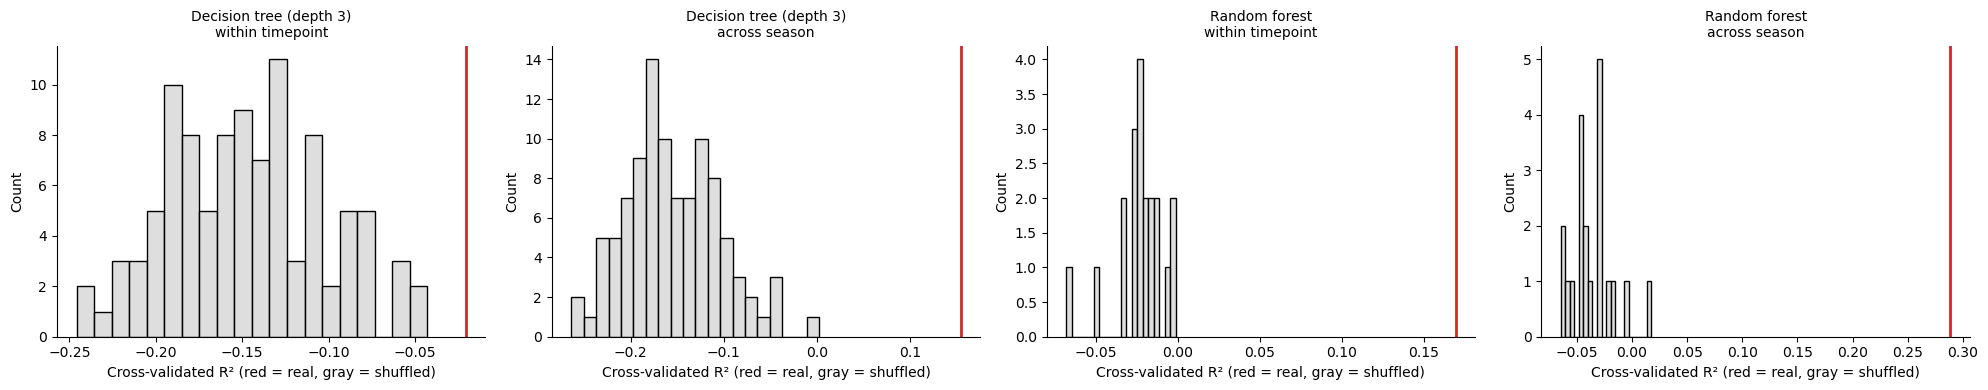

In [34]:
fig, axes = plt.subplots(1, len(null_r2), figsize=(5 * len(null_r2), 4))
fig.patch.set_facecolor("white")
for ax, ((model_name, target_name), null) in zip(axes, null_r2.items()):
    real = cv_results.loc[
        (cv_results["model"] == model_name) & (cv_results["target"] == target_name), "cross-validated R2"
    ].iloc[0]
    sns.histplot(null, bins=20, color="lightgray", ax=ax)
    ax.axvline(real, color="tab:red", linewidth=2)
    ax.set_title(f"{model_name}\n{target_name}", fontsize=10)
    ax.set_xlabel("Cross-validated R² (red = real, gray = shuffled)")
    sns.despine(ax=ax)
plt.tight_layout()

In [35]:
# Random forest feature importance (impurity importance, fitted on all samples)
importance_tables = {}
for target_name, target in targets.items():
    forest = models["Random forest"]().fit(model_features, target)
    importance_tables[target_name] = pd.Series(forest.feature_importances_, index=model_features.columns)
importance = pd.DataFrame(importance_tables).sort_values("within timepoint", ascending=False)
importance.head(20).round(4)

,within timepoint,across season
g__Caldora,0.0661,0.0266
g__Chryseobacterium,0.0569,0.0866
g__Kordiimonas,0.0557,0.0829
g__Aldersonia,0.0485,0.0102
g__Pseudomonas,0.0375,0.0289
g__Klenkia,0.0280,0.0129
g__Brevundimonas,0.0215,0.0269
g__Nakamurella,0.0208,0.0130
g__Ramlibacter,0.0205,0.0104
g__Frigoribacterium,0.0176,0.0106



Tree strata (within timepoint):


,count,mean,std
leaf,,,
7,43,-0.411,0.292
6,90,-0.098,0.350
3,81,-0.064,0.345
10,69,-0.024,0.314
13,15,0.015,0.223
4,50,0.165,0.289
11,36,0.208,0.315
14,40,0.434,0.361



Tree strata (across season):


,count,mean,std
leaf,,,
7,85,-0.388,0.396
6,164,-0.111,0.421
9,126,0.127,0.438
3,17,0.488,0.463
10,17,0.604,0.499
2,15,1.044,0.509


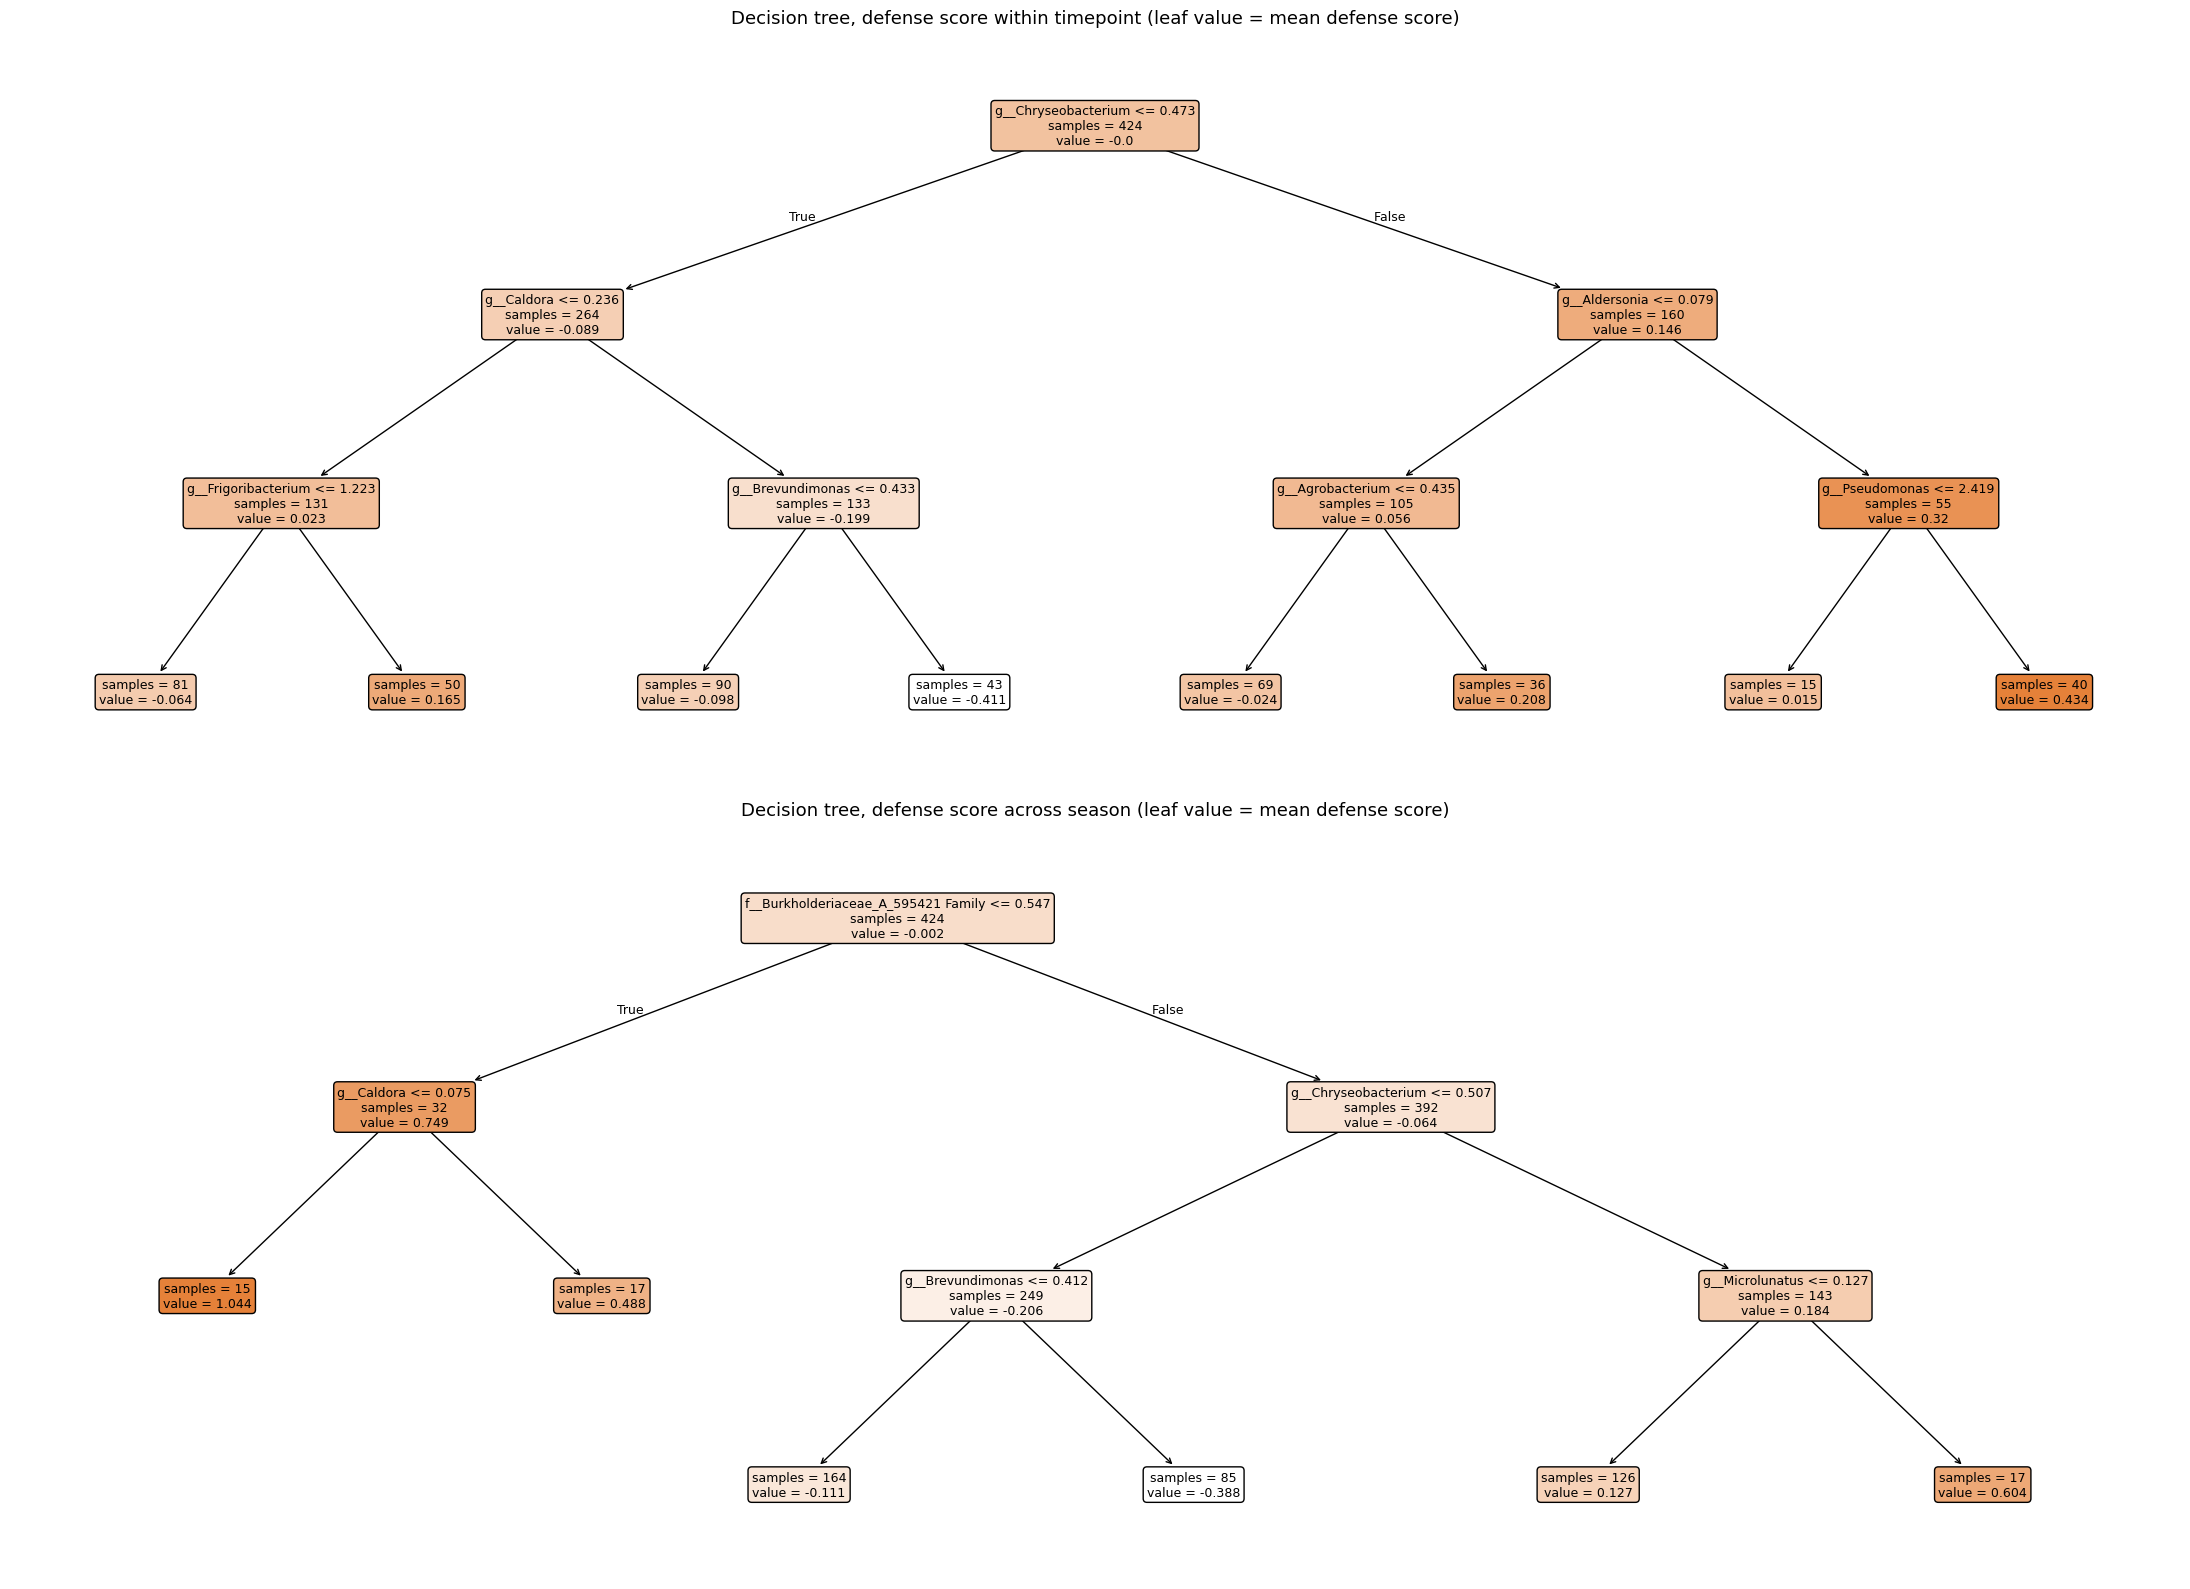

In [36]:
# The decision tree fitted on all samples: each leaf is a microbiome-defined stratum
fig, axes = plt.subplots(2, 1, figsize=(22, 16))
fig.patch.set_facecolor("white")
tree_strata = {}
for ax, (target_name, target) in zip(axes, targets.items()):
    tree = models["Decision tree (depth 3)"]().fit(model_features, target)
    plot_tree(tree, feature_names=model_features.columns, filled=True, rounded=True, fontsize=9, ax=ax, impurity=False)
    ax.set_title(f"Decision tree, defense score {target_name} (leaf value = mean defense score)", fontsize=13)
    leaves = pd.Series(tree.apply(model_features), index=samples)
    tree_strata[target_name] = (
        pd.DataFrame({"leaf": leaves, "defense": target})
        .groupby("leaf")["defense"]
        .agg(["count", "mean", "std"])
        .sort_values("mean")
    )
plt.tight_layout()
for target_name, strata in tree_strata.items():
    print(f"\nTree strata ({target_name}):")
    display(strata.round(3))

In [37]:
pass_summaries[score_label] = {
    "genes": len(gene_sets[score_label]),
    **{
        f"{test}, q < 0.05 ({mode})": int((results[f"q ({mode})"] < 0.05).sum())
        for test, results in [
            ("presence", presence_results),
            ("relative abundance", abundance_results),
            ("log relative abundance", log_abundance_results),
            ("pairs", pair_results),
        ]
        for mode in ["within timepoint", "across season"]
    },
    **{
        f"{row.model} R2 ({row.target})": round(row._3, 3)
        for row in cv_results.itertuples()
    },
    "top within-timepoint genera (log abundance)": ", ".join(
        g.replace("g__", "")
        for g in log_abundance_results.sort_values("p (within timepoint)").index[:6]
    ),
}
print("Summary saved for", score_label)

Summary saved for r > 0.3


# Summary: r > 0.5 vs r > 0.3 (vs r > 0.4)

Number of genera / pairs at q < 0.05 for each test, and cross-validated R² of the tree and forest. The r > 0.4 column for the genus and pair tests comes from the result files of `microbiome_features_stratifying_log2_defense_score.ipynb`, so it reflects that notebook's last run.

In [38]:
summary = pd.DataFrame(pass_summaries)
reference = {}
for test, file_name in [
    ("presence", "presence"),
    ("relative abundance", "abundance"),
    ("log relative abundance", "log_abundance"),
    ("pairs", "pairs"),
]:
    try:
        results = pd.read_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_{file_name}_log2_score.csv")
        for mode in ["within timepoint", "across season"]:
            reference[f"{test}, q < 0.05 ({mode})"] = int((results[f"q ({mode})"] < 0.05).sum())
    except FileNotFoundError:
        pass
reference["genes"] = len(gene_sets["r > 0.4"])
summary["r > 0.4 (reference)"] = pd.Series(reference)
summary

,r > 0.5,r > 0.3,r > 0.4 (reference)
genes,46,333,148.0
"presence, q < 0.05 (within timepoint)",8,6,6.0
"presence, q < 0.05 (across season)",50,30,36.0
"relative abundance, q < 0.05 (within timepoint)",10,9,9.0
"relative abundance, q < 0.05 (across season)",34,29,31.0
"log relative abundance, q < 0.05 (within timepoint)",17,20,19.0
"log relative abundance, q < 0.05 (across season)",47,37,44.0
"pairs, q < 0.05 (within timepoint)",92,95,94.0
"pairs, q < 0.05 (across season)",1306,693,950.0
Decision tree (depth 3) R2 (within timepoint),0.02,-0.02,NaN
